# Assignment 4: CNN Architecture — Transfer Learning on CIFAR-10

| | |
|---|---|
| **Course** | AAI 6640 — Applied Deep Learning |
| **Module** | Week 10 (10.8) |
| **Author** | Muhammad Obaidullah |
| **Dataset** | CIFAR-10 (Keras) |
| **Task** | 10-class image classification with two ImageNet-pretrained CNNs, ResNet50 and EfficientNetB0: feature extraction first, then fine-tuning |

## Overview

**Objective:** measure how two pretrained architectures transfer to CIFAR-10, first as frozen feature extractors and then after fine-tuning their upper layers, and select one final model on validation evidence alone.

**Approach:** load → inspect → stratified split → resize and preprocess in the input pipeline → feature extraction → fine-tuning → compare → select → evaluate once on test.

**Controlled comparison.** Only two things vary: the **architecture**, which brings its own preprocessing function, and the **training stage**. Everything else stays fixed:

| Held constant | Setting |
|---|---|
| Data split | 45,000 train / 5,000 validation (stratified, `SEED = 42`) / 10,000 test (original) |
| Input resolution | 128 × 128, bilinear resize inside `tf.data` |
| Classification head | Global average pooling → `Dense(10, softmax)`; no dropout |
| Loss, metric | Sparse categorical cross-entropy; accuracy |
| Optimizer, batch size | Adam; 64 |
| Feature extraction | Learning rate 1e-3, at most 15 epochs |
| Fine-tuning | Learning rate 1e-5, at most 10 further epochs, starting from the feature-extraction weights |
| Callbacks | `EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True)` and an epoch timer |
| Unfreezing rule | Last 15% of the base's layers, moved back to the start of the block that holds the cut; batch-normalization layers stay frozen |

**Reporting rule.** Each stage is reported at its **best-validation-accuracy epoch**, the epoch whose weights `restore_best_weights` keeps. Training metrics, validation loss, and the generalization gap (training accuracy minus validation accuracy) are read at that epoch. Training time is the wall-clock sum of the stage's epochs, including the validation pass. Model loading is excluded. The first epoch of every stage also includes graph tracing and XLA compilation, so per-epoch cost is reported as the median epoch time.

**No dropout in the head.** The brief allows one dropout layer if both models share it. The head is left exactly as specified: it is a single linear layer on pooled features, so there is little capacity to regularize, early stopping already guards against overfitting, and one fewer setting keeps the comparison cleaner.

**Runtime.** Use a GPU runtime (Colab T4 or better). On a CPU the full notebook takes many hours. The outputs below were produced on one NVIDIA L40S in about 10 minutes end to end; all timings refer to that GPU.

## Setup

All imports, constants, and display settings. `keras.utils.set_random_seed(SEED)` seeds Python, NumPy, and TensorFlow: it fixes the split, the shuffle order, and the head's initial weights. GPU convolution kernels can still vary slightly between runs. `enable_op_determinism()` is left off because it forces slower deterministic GPU kernels, which would multiply training time.

In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # before TensorFlow loads; hides C++ notices

import re
import time
import warnings
from dataclasses import dataclass
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from IPython.display import display
from keras.applications import EfficientNetB0, ResNet50, efficientnet, resnet50
from matplotlib.ticker import MaxNLocator, PercentFormatter
from matplotlib_inline.backend_inline import set_matplotlib_formats
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow.keras.datasets import cifar10

SEED = 42
IMG_SIZE = 128
BATCH_SIZE = 64
VAL_SIZE = 5_000
FE_LEARNING_RATE = 1e-3
FE_MAX_EPOCHS = 15
FT_LEARNING_RATE = 1e-5
FT_MAX_EPOCHS = 10
PATIENCE = 3
UNFREEZE_FRACTION = 0.15
ARTIFACTS = Path("artifacts")  # best weights of every stage, for reloading the final model
AUTOTUNE = tf.data.AUTOTUNE

CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
]
NUM_CLASSES = len(CLASS_NAMES)
COLORS = {"ResNet50": "#2a78d6", "EfficientNetB0": "#eb6834"}  # one fixed color per architecture

keras.utils.set_random_seed(SEED)
ARTIFACTS.mkdir(exist_ok=True)

set_matplotlib_formats("retina")
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "font.size": 11,
        "axes.titleweight": "bold",
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.alpha": 0.3,
        "legend.frameon": False,
    }
)
pd.set_option("display.precision", 4)

gpus = tf.config.list_physical_devices("GPU")
gpu_names = [tf.config.experimental.get_device_details(gpu).get("device_name", gpu.name) for gpu in gpus]
print(
    f"TensorFlow {tf.__version__} | Keras {keras.__version__} | "
    f"scikit-learn {sklearn.__version__} | NumPy {np.__version__} | "
    f"pandas {pd.__version__}"
)
print(f"GPU: {', '.join(gpu_names) if gpu_names else 'none (training will be very slow)'}")

TensorFlow 2.20.0 | Keras 3.15.1 | scikit-learn 1.9.1 | NumPy 2.5.4 | pandas 3.1.1
GPU: NVIDIA L40S


## Step 1 — Prepare the data

CIFAR-10 (Krizhevsky, 2009): 60,000 color images of 32 × 32 pixels in 10 mutually exclusive classes, 50,000 for training and 10,000 for testing.

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = cifar10.load_data()
y_train_full, y_test = y_train_full.ravel(), y_test.ravel()  # labels arrive as (n, 1)

print(f"Training images: {x_train_full.shape} {x_train_full.dtype}; labels {y_train_full.shape}")
print(f"Test images:     {x_test.shape} {x_test.dtype}; labels {y_test.shape}")
print(f"Pixel values:    {x_train_full.min()} to {x_train_full.max()}")
print(f"Classes ({NUM_CLASSES}): " + ", ".join(f"{i} = {name}" for i, name in enumerate(CLASS_NAMES)))

Training images: (50000, 32, 32, 3) uint8; labels (50000,)
Test images:     (10000, 32, 32, 3) uint8; labels (10000,)
Pixel values:    0 to 255
Classes (10): 0 = airplane, 1 = automobile, 2 = bird, 3 = cat, 4 = deer, 5 = dog, 6 = frog, 7 = horse, 8 = ship, 9 = truck


### Class distribution

In [3]:
def class_counts(labels: np.ndarray) -> pd.Series:
    """Images per class, in label order."""
    return pd.Series(np.bincount(labels, minlength=NUM_CLASSES), index=CLASS_NAMES)


pd.DataFrame(
    {"Training (original)": class_counts(y_train_full), "Test": class_counts(y_test)}
).rename_axis("Class")

,Training (original),Test
Class,,
airplane,5000,1000
automobile,5000,1000
bird,5000,1000
cat,5000,1000
deer,5000,1000
dog,5000,1000
frog,5000,1000
horse,5000,1000
ship,5000,1000


### Example images

Three random training images per class at their native 32 × 32 resolution.

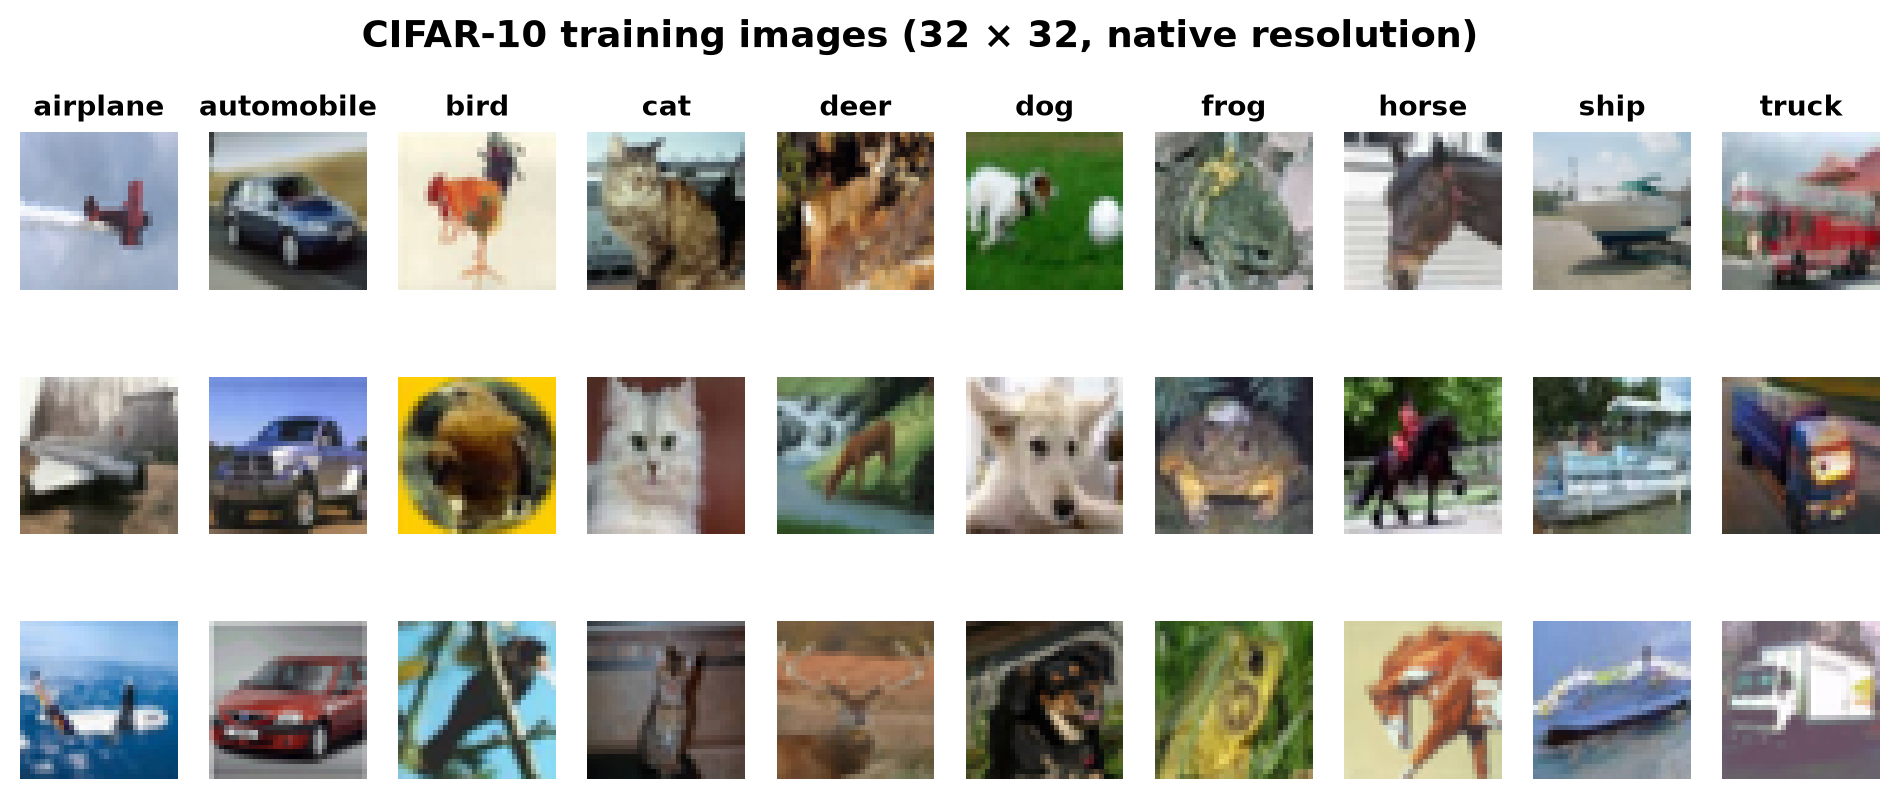

In [4]:
def show_examples(images: np.ndarray, labels: np.ndarray, per_class: int = 3) -> None:
    """A grid with `per_class` random images for every class, one column per class."""
    rng = np.random.default_rng(SEED)
    fig, axes = plt.subplots(per_class, NUM_CLASSES, figsize=(12, 1.3 * per_class + 0.6))
    for column, name in enumerate(CLASS_NAMES):
        picks = rng.choice(np.flatnonzero(labels == column), per_class, replace=False)
        for row, index in enumerate(picks):
            ax = axes[row, column]
            ax.imshow(images[index])
            ax.axis("off")
            if row == 0:
                ax.set_title(name, fontsize=10)
    fig.suptitle("CIFAR-10 training images (32 × 32, native resolution)", fontweight="bold")
    plt.show()


show_examples(x_train_full, y_train_full)

### Training / validation split

5,000 of the 50,000 original training images become the validation set. `stratify` keeps every class at the same share in both parts, and `random_state=SEED` makes the shuffled split reproducible. The 10,000 test images stay untouched until Step 6.

In [5]:
@dataclass(frozen=True)
class Split:
    """One partition: uint8 images (n, 32, 32, 3) and integer labels (n,)."""

    x: np.ndarray
    y: np.ndarray


x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=VAL_SIZE, stratify=y_train_full, random_state=SEED
)
splits = {
    "train": Split(x_train, y_train),
    "val": Split(x_val, y_val),
    "test": Split(x_test, y_test),
}

counts = pd.DataFrame({name: class_counts(part.y) for name, part in splits.items()})
shares = 100 * counts / counts.sum()
distribution = counts.join(shares.add_suffix(" (%)")).rename_axis("Class")
distribution.loc["Total"] = distribution.sum()
distribution

,train,val,test,train (%),val (%),test (%)
Class,,,,,,
airplane,4500,500,1000,10.0,10.0,10.0
automobile,4500,500,1000,10.0,10.0,10.0
bird,4500,500,1000,10.0,10.0,10.0
cat,4500,500,1000,10.0,10.0,10.0
deer,4500,500,1000,10.0,10.0,10.0
dog,4500,500,1000,10.0,10.0,10.0
frog,4500,500,1000,10.0,10.0,10.0
horse,4500,500,1000,10.0,10.0,10.0
ship,4500,500,1000,10.0,10.0,10.0


### Input pipeline: resize and model-specific preprocessing

The images stay in memory at 32 × 32 as `uint8` (184 MB for all 60,000). `tf.data` resizes each batch to 128 × 128 on the fly and applies the architecture's own `preprocess_input`, so no resized copy is ever stored: at 128 × 128 in `float32` the three splits would take about 12 GB. Only the training set is shuffled; validation and test keep a fixed order.

In [6]:
PREPROCESS = {
    "ResNet50": resnet50.preprocess_input,
    "EfficientNetB0": efficientnet.preprocess_input,
}


def make_dataset(part: Split, preprocess, training: bool) -> tf.data.Dataset:
    """Batched (image, label) pairs, resized to IMG_SIZE and preprocessed for one architecture."""

    def transform(images, labels):
        images = tf.image.resize(tf.cast(images, tf.float32), (IMG_SIZE, IMG_SIZE))  # bilinear
        return preprocess(images), labels

    dataset = tf.data.Dataset.from_tensor_slices((part.x, part.y))
    if training:
        dataset = dataset.shuffle(len(part.y), seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(BATCH_SIZE).map(transform, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)


datasets = {
    name: {part: make_dataset(split, preprocess, part == "train") for part, split in splits.items()}
    for name, preprocess in PREPROCESS.items()
}

**Checking what each model receives.** The first validation batch after each pipeline. Channel order is whatever the preprocessing function outputs: BGR for ResNet50, RGB for EfficientNetB0.

In [7]:
def batch_profile(dataset: tf.data.Dataset) -> dict[str, object]:
    """Shape, range, and per-channel means of the first batch of a pipeline."""
    images = next(iter(dataset))[0].numpy()
    return {
        "Batch shape": str(images.shape),
        "dtype": str(images.dtype),
        "Min": images.min(),
        "Max": images.max(),
        **{f"Channel {c} mean": images[..., c].mean() for c in range(3)},
    }


pd.DataFrame({name: batch_profile(parts["val"]) for name, parts in datasets.items()}).T

,Batch shape,dtype,Min,Max,Channel 0 mean,Channel 1 mean,Channel 2 mean
ResNet50,"(64, 128, 128, 3)",float32,-123.5081,151.061,10.3793,7.1722,4.2264
EfficientNetB0,"(64, 128, 128, 3)",float32,0.0156,255.0,127.9064,123.9512,114.3183


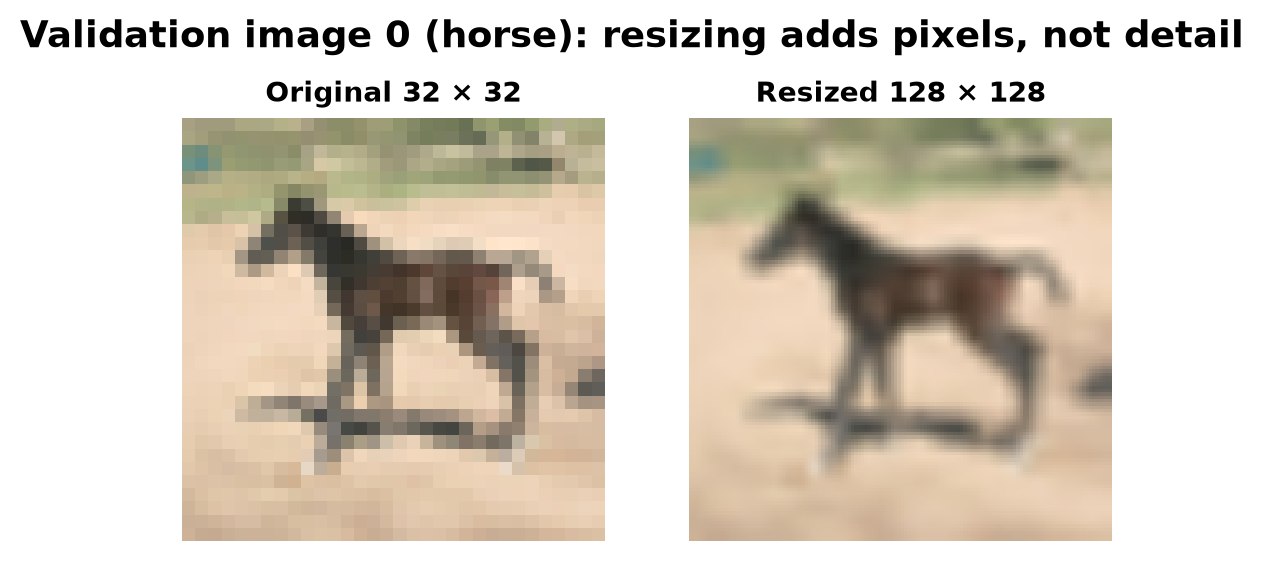

In [8]:
original = x_val[0]
resized = tf.image.resize(tf.cast(original, tf.float32), (IMG_SIZE, IMG_SIZE))
resized = np.clip(resized.numpy(), 0, 255).astype(np.uint8)  # back to displayable pixels

fig, axes = plt.subplots(1, 2, figsize=(6, 3.2))
for ax, image, title in zip(axes, (original, resized), ("Original 32 × 32", f"Resized {IMG_SIZE} × {IMG_SIZE}")):
    ax.imshow(image)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
fig.suptitle(f"Validation image 0 ({CLASS_NAMES[y_val[0]]}): resizing adds pixels, not detail", fontweight="bold")
plt.show()

### Why these data-preparation choices

**Why resizing is necessary.** Both networks were pretrained on ImageNet at 224 × 224, and both downsample by a total factor of 32 through their strided stages. Their filters, the depth at which each receptive field covers an object part, and the size of the final feature map all assume objects that span many pixels. Fed at 32 × 32, each network's last stage would operate on a 1 × 1 grid, discarding all spatial layout, and objects would appear far smaller than anything seen in pretraining. At 128 × 128 the final feature map is 4 × 4, and objects appear at a scale closer to the pretraining data. Resizing adds no information, because bilinear interpolation only spreads the 1,024 original pixels over more positions. It helps by matching scale, not by adding detail. The cost is compute: 16 times the pixels of the original, while 224 × 224 would cost about three times more again, since (224 / 128)² ≈ 3.1.

**Why both architectures use the same resolution.** Resolution changes accuracy and compute for any CNN. If the two models saw different resolutions, a difference in validation accuracy or training time could come from the resolution instead of the architecture. Holding it at 128 × 128 for both makes architecture the only variable. Neither model runs at its native 224 × 224, so both carry the same kind of distribution shift.

**Why each model needs its own preprocessing.** The first-layer weights were learned on inputs with a specific encoding, and the encodings differ. Keras's ResNet50 uses "caffe" preprocessing: RGB is reordered to BGR and the ImageNet channel means are subtracted (103.939, 116.779, 123.68), with no rescaling, so values run from about −124 to +151. EfficientNetB0 builds its normalization into the model (a `Rescaling` and a `Normalization` layer right after the input), so its `preprocess_input` passes values through unchanged and the model expects raw RGB in [0, 255]. The batch profile above shows both encodings. Swapping them raises no error. It silently feeds each network inputs its filters were never trained on, degrading the pretrained features.

**Why the test set stays separate.** Every decision in this notebook uses the validation set: which epoch to keep (early stopping), whether fine-tuning helped, and which architecture and stage become the final model. If test results influenced any of these choices, the test set would become part of model selection and its accuracy would be optimistically biased. The test set is therefore used exactly once, in Step 6, on the one model already chosen. Validation accuracy is itself slightly optimistic, because early stopping and model selection both maximize it, and that is exactly why a separate, untouched test estimate is needed.

## Step 2 — Select two pretrained architectures

**ResNet50** and **EfficientNetB0**, both loaded with `weights="imagenet"` and `include_top=False` (no 1,000-class ImageNet head). The pair contrasts a large, conventional residual network with a small network designed for efficiency.

In [9]:
BACKBONES = {"ResNet50": ResNet50, "EfficientNetB0": EfficientNetB0}


def load_base(name: str) -> keras.Model:
    """The pretrained convolutional base of one architecture, without its ImageNet classifier."""
    return BACKBONES[name](
        include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )


def throughput(base: keras.Model, dataset: tf.data.Dataset, n_batches: int = 20) -> float:
    """Inference images per second of a base on this machine, after one warm-up batch."""
    forward = tf.function(lambda images: base(images, training=False))
    batches = [images for images, _ in dataset.take(n_batches + 1)]
    float(tf.reduce_sum(forward(batches[0])))  # warm-up: tracing and kernel selection
    start = time.perf_counter()
    for images in batches[1:]:
        float(tf.reduce_sum(forward(images)))  # waits for the GPU before the clock stops
    return sum(len(images) for images in batches[1:]) / (time.perf_counter() - start)


bases = {name: load_base(name) for name in BACKBONES}
pd.DataFrame(
    {
        name: {
            "Layers (Keras objects)": len(base.layers),
            "Parameters": f"{base.count_params():,}",
            "Output feature map": str(tuple(base.output.shape[1:])),
            "Pooled feature size": base.output.shape[-1],
            f"Inference images/s at {IMG_SIZE}×{IMG_SIZE}": f"{round(throughput(base, datasets[name]['val'])):,}",
        }
        for name, base in bases.items()
    }
).T

,Layers (Keras objects),Parameters,Output feature map,Pooled feature size,Inference images/s at 128×128
ResNet50,175,"23,587,712","(4, 4, 2048)",2048,"4,793"
EfficientNetB0,238,"4,049,571","(4, 4, 1280)",1280,"6,426"


### The two architectures

**ResNet50** (He et al., 2016) stacks 16 *bottleneck residual blocks* in four stages (3, 4, 6, and 3 blocks) after a 7 × 7 stem. Each block computes a 1 × 1 → 3 × 3 → 1 × 1 convolution sequence F(x) and adds its input back: y = F(x) + x. The identity shortcut lets gradients bypass each block, which is what made 50-plus-layer networks trainable, and it means each block learns only a *correction* to its input. Every convolution is followed by batch normalization, and the last stage outputs 2,048 channels.

**EfficientNetB0** (Tan & Le, 2019) is the baseline of the EfficientNet family, found by neural architecture search that optimized accuracy against FLOPs. It uses 16 *MBConv* blocks in seven stages. Each block is an inverted residual (Sandler et al., 2018): a 1 × 1 convolution expands the channels (except in the first stage), a cheap *depthwise* 3 × 3 or 5 × 5 convolution filters each channel separately, a *squeeze-and-excitation* unit (Hu et al., 2018) reweights channels from global context, and a linear 1 × 1 convolution projects back down. It uses the swish activation and ends with a 1 × 1 convolution to 1,280 channels. B1 to B7 are obtained from B0 by *compound scaling*: depth, width, and resolution are enlarged together by fixed ratios.

**How they differ.** ResNet50 gets its capacity from wide dense convolutions (its bottleneck 3 × 3 convolutions mix every channel with every other). EfficientNetB0 factorizes spatial and channel mixing (depthwise, then pointwise), adds channel attention, and is about six times smaller. Tan and Le (2019, Table 2) report, at 224 × 224 with the ImageNet head, 26 M parameters and 4.1 B FLOPs for ResNet-50 against 5.3 M and 0.39 B for B0, with B0 the more accurate on ImageNet (77.1% vs 76.0% top-1). Without the head, the Keras bases hold about 23.6 M and 4.0 M parameters (table above). At 128 × 128 each network needs about (128 / 224)² ≈ 0.33 of those FLOPs. The FLOP gap of roughly 10× does not become a 10× speed gap on a GPU: depthwise convolutions and squeeze-and-excitation are memory-bound and use GPU cores less efficiently than dense convolutions. In the benchmark above EfficientNetB0 is about 1.3 times faster (6,426 against 4,793 images/s). That is one short measurement on a shared GPU node, so the epoch times in Steps 3 and 4 are the better cost figures.

**Why both suit transfer learning.** Both were trained on ImageNet-1k, whose 1,000 classes include many close relatives of the CIFAR-10 categories (aircraft, cars, trucks, ships, birds, cats, dogs, frogs, horses, and deer-like animals). Their early stages learn generic edges, textures, and colors, and their later stages learn object parts. Global average pooling of the final feature map gives a compact image descriptor (2,048 or 1,280 values) that a linear classifier can use directly. Both are organized in named blocks and stages, so a well-defined upper portion can be unfrozen for fine-tuning. Both also rely on batch normalization throughout, which is why Step 4 has to handle those layers explicitly.

## Step 3 — Feature extraction

For each architecture: freeze the whole pretrained base, add the shared head (global average pooling → `Dense(10, softmax)`), and train only the head.

The base is called with `training=False`. Its batch-normalization layers then use their stored ImageNet statistics in inference mode, and they keep doing so in Step 4 after layers are unfrozen, as recommended in the Keras transfer-learning guide (Chollet, n.d.). It also switches off EfficientNetB0's stochastic-depth dropout inside the base, so neither network has any active regularization layer, and training and validation metrics are computed by the same deterministic forward pass. One difference remains: the training metrics are running averages over an epoch in which the weights keep changing, while validation is measured once at the end of the epoch.

In [10]:
@dataclass(frozen=True)
class StageResult:
    """The outcome of one training stage of one architecture."""

    architecture: str
    stage: str
    history: pd.DataFrame  # one row per epoch: loss, accuracy, val_loss, val_accuracy, seconds
    max_epochs: int
    total_params: int
    trainable_params: int
    weights_path: Path  # best-validation-accuracy weights of this stage


class EpochTimer(keras.callbacks.Callback):
    """Wall-clock seconds of every epoch, including its validation pass."""

    def on_train_begin(self, logs=None):
        self.seconds = []

    def on_epoch_begin(self, epoch, logs=None):
        self._start = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        self.seconds.append(time.perf_counter() - self._start)


def count_trainable(model: keras.Model) -> int:
    """Number of scalar weights the optimizer updates."""
    return int(sum(np.prod(weight.shape) for weight in model.trainable_weights))


def build_model(name: str, base: keras.Model) -> keras.Model:
    """Frozen pretrained base followed by the shared head: GAP → Dense(10, softmax)."""
    base.trainable = False
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    features = base(inputs, training=False)  # batch normalization stays in inference mode
    pooled = keras.layers.GlobalAveragePooling2D(name="global_average_pooling")(features)
    outputs = keras.layers.Dense(NUM_CLASSES, activation="softmax", name="classifier")(pooled)
    return keras.Model(inputs, outputs, name=f"{name}_cifar10")


def train_stage(
    model: keras.Model,
    data: dict[str, tf.data.Dataset],
    *,
    architecture: str,
    stage: str,
    learning_rate: float,
    max_epochs: int,
    initial_epoch: int = 0,
) -> StageResult:
    """Compile, train with early stopping, keep the best-validation weights, and save them."""
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    timer = EpochTimer()
    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_accuracy", mode="max", patience=PATIENCE, restore_best_weights=True, verbose=1
    )
    fit = model.fit(
        data["train"],
        validation_data=data["val"],
        epochs=initial_epoch + max_epochs,
        initial_epoch=initial_epoch,
        callbacks=[early_stopping, timer],
        shuffle=False,  # the training dataset already reshuffles itself every epoch
        verbose=2,
    )
    epochs = pd.RangeIndex(initial_epoch + 1, initial_epoch + 1 + len(timer.seconds), name="epoch")
    columns = ["loss", "accuracy", "val_loss", "val_accuracy"]
    history = pd.DataFrame({column: fit.history[column] for column in columns}, index=epochs)
    history["seconds"] = timer.seconds
    weights_path = ARTIFACTS / f"{architecture}_{stage.lower().replace(' ', '_')}.weights.h5"
    model.save_weights(weights_path)  # EarlyStopping has already restored the best epoch
    return StageResult(
        architecture, stage, history, max_epochs,
        model.count_params(), count_trainable(model), weights_path,
    )

In [11]:
def summarize(result: StageResult) -> dict[str, object]:
    """One stage at its best-validation-accuracy epoch (the reporting rule)."""
    history = result.history
    best_epoch = int(history["val_accuracy"].idxmax())
    best = history.loc[best_epoch]
    return {
        "Architecture": result.architecture,
        "Stage": result.stage,
        "Epochs run": len(history),
        "Max epochs": result.max_epochs,
        "Best epoch": best_epoch,
        "Best val accuracy": best["val_accuracy"],
        "Val loss at best": best["val_loss"],
        "Train accuracy at best": best["accuracy"],
        "Train loss at best": best["loss"],
        "Gap (train − val accuracy)": best["accuracy"] - best["val_accuracy"],
        "Lowest val loss": history["val_loss"].min(),
        "Val-loss increases": int((history["val_loss"].diff() > 0).sum()),
        "Total params": result.total_params,
        "Trainable params": result.trainable_params,
        "Training time (s)": history["seconds"].sum(),
        "Median epoch time (s)": history["seconds"].median(),
    }


METRIC_FORMATS = {
    **dict.fromkeys(
        ["Best val accuracy", "Val loss at best", "Train accuracy at best", "Train loss at best",
         "Gap (train − val accuracy)", "Lowest val loss"],
        "{:.4f}",
    ),
    **dict.fromkeys(["Total params", "Trainable params"], "{:,}"),
    **dict.fromkeys(["Training time (s)", "Median epoch time (s)", "Cumulative time (s)"], "{:.1f}"),
}


def summary_table(results: list[StageResult]):
    """Stages as columns, metrics as rows, for side-by-side reading."""
    table = pd.DataFrame([summarize(result) for result in results]).set_index(["Architecture", "Stage"])
    table = table.astype(object).T  # object keeps integer rows as integers
    styler = table.style
    for metric, fmt in METRIC_FORMATS.items():
        if metric in table.index:
            styler = styler.format(fmt, subset=pd.IndexSlice[[metric], :])
    return styler


def plot_learning_curves(stages_by_architecture: dict[str, list[StageResult]], title: str) -> None:
    """Accuracy and loss per epoch for each architecture, with every stage's best epoch marked."""
    n_rows = len(stages_by_architecture)
    fig, axes = plt.subplots(n_rows, 2, figsize=(12, 3.8 * n_rows), squeeze=False)
    for row, (name, stages) in zip(axes, stages_by_architecture.items()):
        history = pd.concat([stage.history for stage in stages])
        color = COLORS[name]
        for ax, metric, label in zip(row, ("accuracy", "loss"), ("Accuracy", "Cross-entropy loss")):
            ax.plot(history.index, history[metric], color=color, lw=2, label="Training")
            ax.plot(history.index, history[f"val_{metric}"], color=color, lw=2, ls="--", label="Validation")
            for index, stage in enumerate(stages):
                best = stage.history["val_accuracy"].idxmax()
                ax.plot(
                    best, stage.history.loc[best, f"val_{metric}"], "o", ms=8, color=color,
                    mec="white", mew=2, label="Best val accuracy epoch" if index == 0 else None,
                )
                if index > 0:
                    ax.axvline(
                        stage.history.index[0] - 0.5, color="0.45", lw=1, ls=":",
                        label=f"{stage.stage} starts",
                    )
            ax.set(title=f"{name}: {label.lower()}", xlabel="Epoch", ylabel=label)
            ax.set_xlim(0.5, history.index[-1] + 0.5)
            ax.xaxis.get_major_locator().set_params(integer=True)
        row[0].legend(loc="best")
    fig.suptitle(title, fontweight="bold")
    fig.tight_layout()
    plt.show()

### Train the heads

The seed is reset before each model is built, so both runs start from the same random state. The training pipelines already share one fixed shuffle seed.

In [12]:
models, fe_results = {}, {}
for name, base in bases.items():
    print(f"\n=== {name}: feature extraction ===")
    keras.utils.set_random_seed(SEED)
    models[name] = build_model(name, base)
    fe_results[name] = train_stage(
        models[name], datasets[name], architecture=name, stage="Feature extraction",
        learning_rate=FE_LEARNING_RATE, max_epochs=FE_MAX_EPOCHS,
    )


=== ResNet50: feature extraction ===
Epoch 1/15
704/704 - 25s - 36ms/step - accuracy: 0.8382 - loss: 0.4791 - val_accuracy: 0.8762 - val_loss: 0.3761
Epoch 2/15
704/704 - 9s - 13ms/step - accuracy: 0.8887 - loss: 0.3261 - val_accuracy: 0.8768 - val_loss: 0.3715
Epoch 3/15
704/704 - 9s - 12ms/step - accuracy: 0.9035 - loss: 0.2840 - val_accuracy: 0.8918 - val_loss: 0.3399
Epoch 4/15
704/704 - 9s - 12ms/step - accuracy: 0.9129 - loss: 0.2500 - val_accuracy: 0.8882 - val_loss: 0.3594
Epoch 5/15
704/704 - 9s - 12ms/step - accuracy: 0.9200 - loss: 0.2293 - val_accuracy: 0.8888 - val_loss: 0.3461
Epoch 6/15
704/704 - 9s - 12ms/step - accuracy: 0.9247 - loss: 0.2149 - val_accuracy: 0.8868 - val_loss: 0.3760
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 3.

=== EfficientNetB0: feature extraction ===
Epoch 1/15
704/704 - 35s - 50ms/step - accuracy: 0.8390 - loss: 0.5190 - val_accuracy: 0.8774 - val_loss: 0.3559
Epoch 2/15
704/704 - 8s - 11ms/step - accuracy: 0

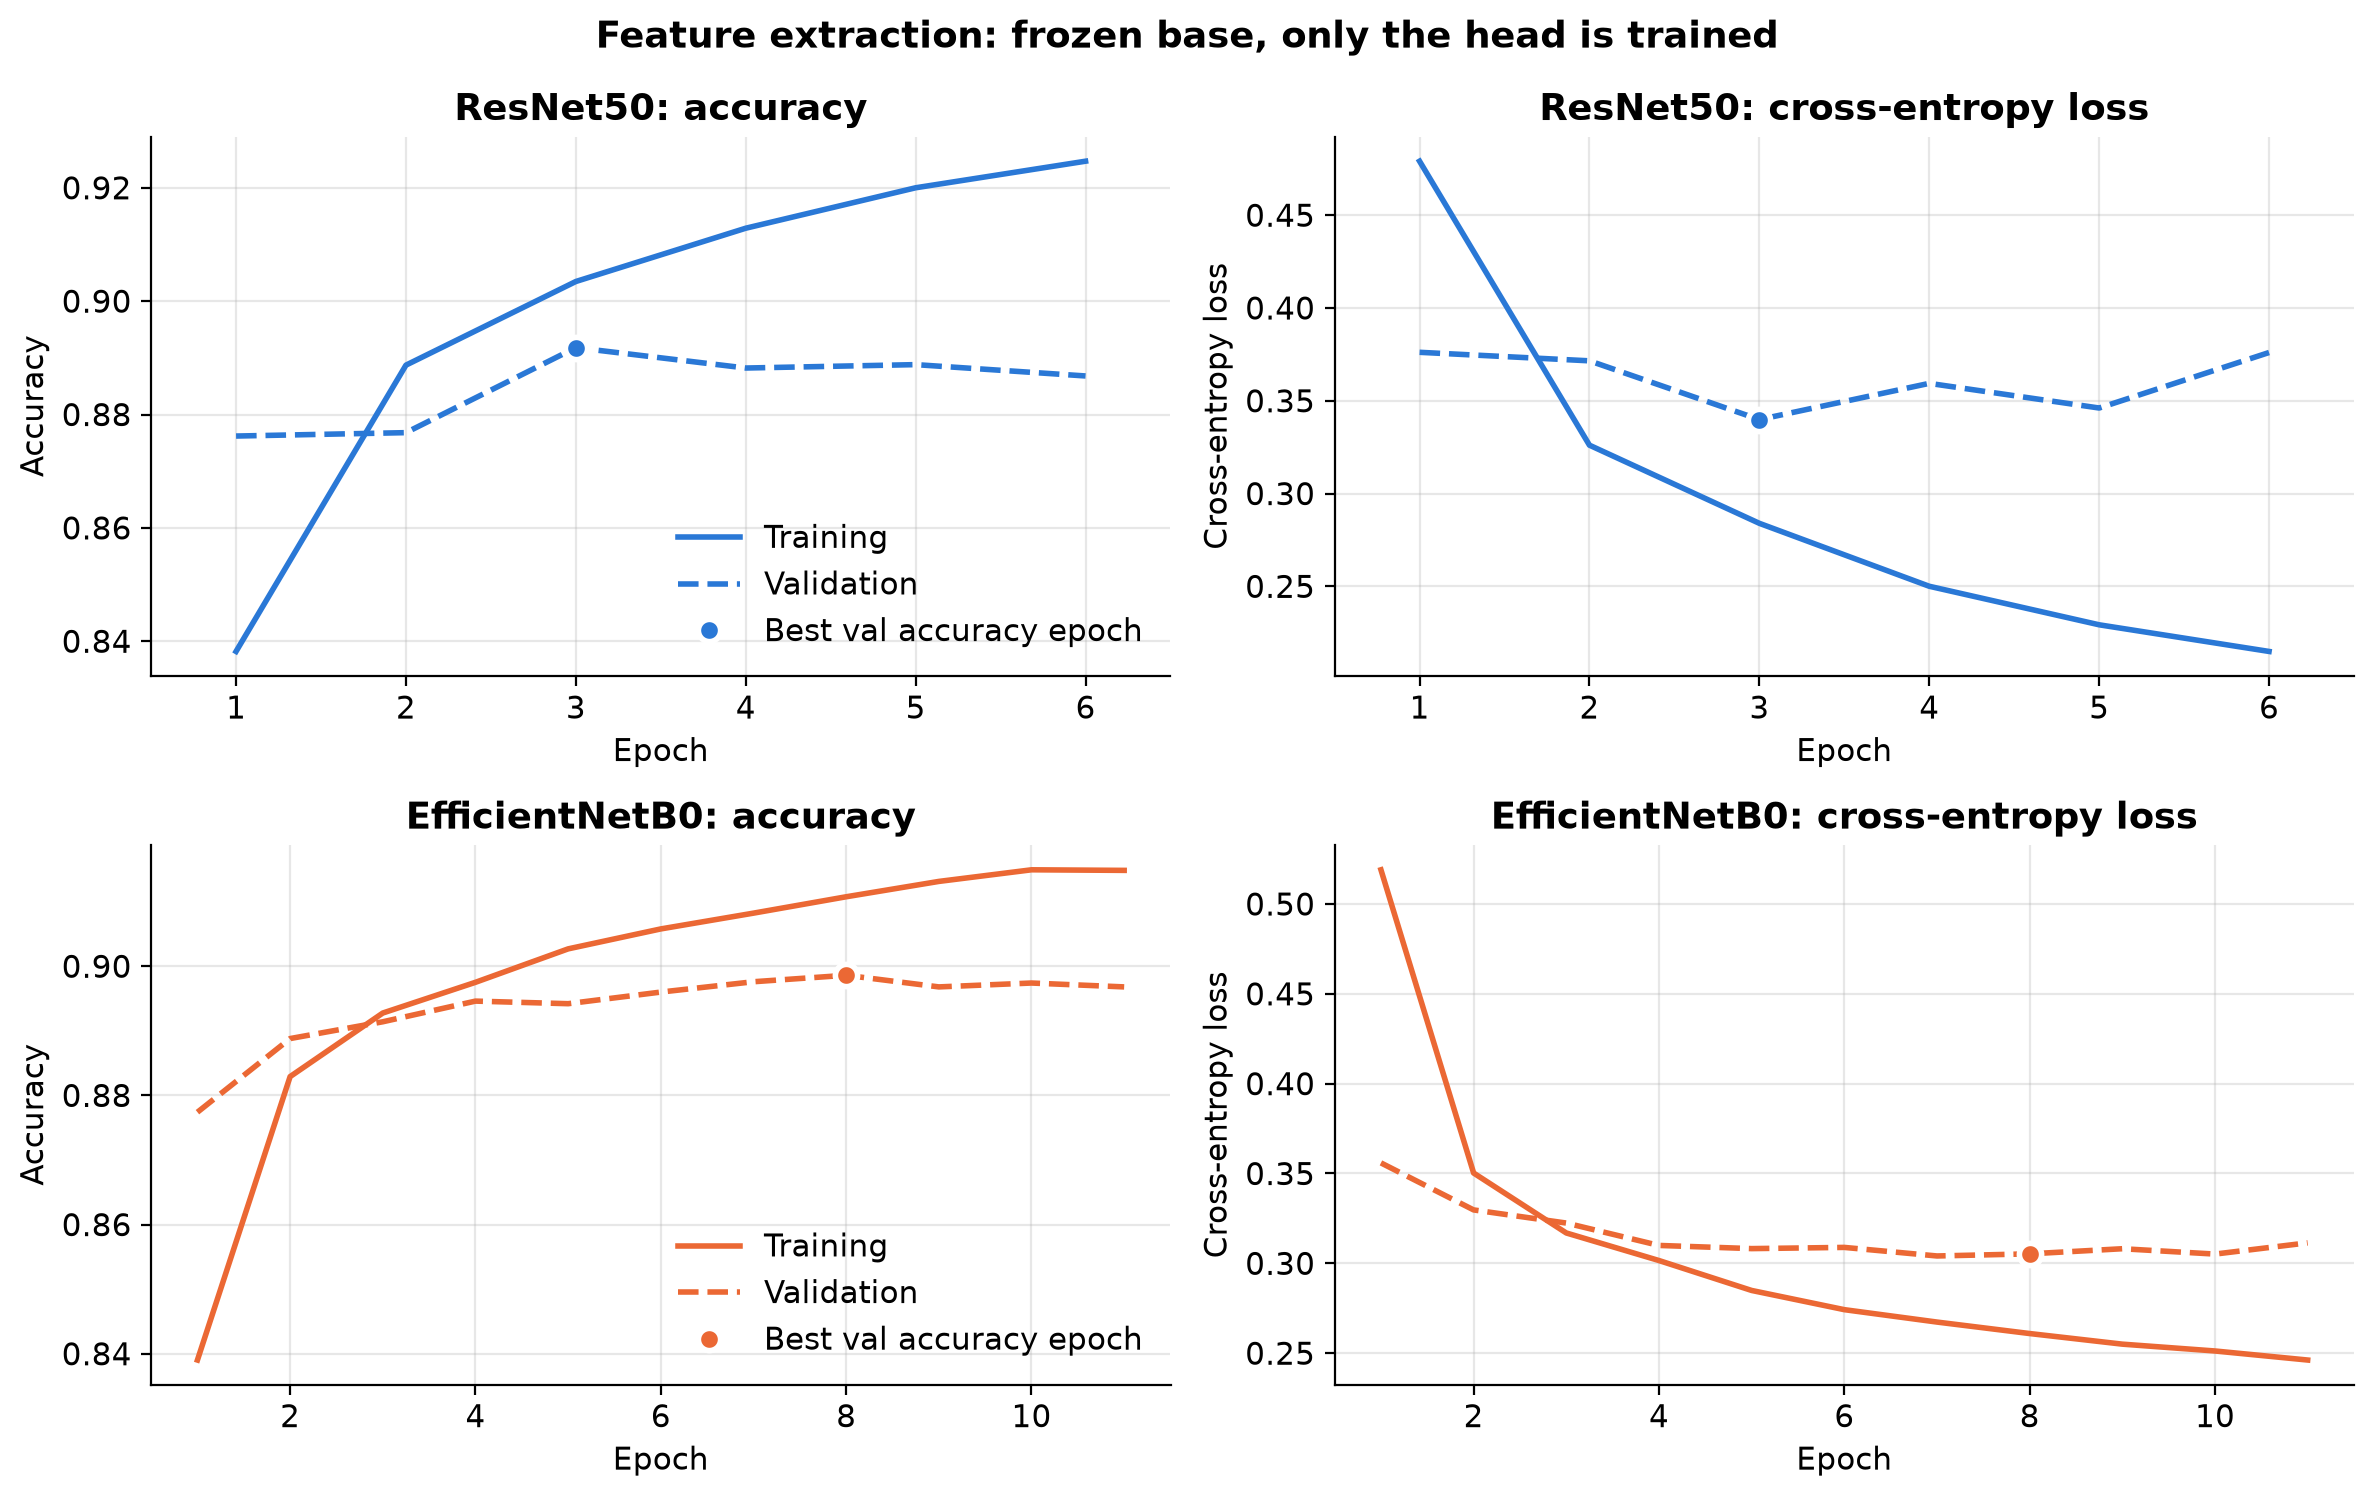

Architecture,ResNet50,EfficientNetB0
Stage,Feature extraction,Feature extraction
Epochs run,6,11
Max epochs,15,15
Best epoch,3,8
Best val accuracy,0.8918,0.8986
Val loss at best,0.3399,0.3053
Train accuracy at best,0.9035,0.9108
Train loss at best,0.2840,0.2609
Gap (train − val accuracy),0.0117,0.0122
Lowest val loss,0.3399,0.3041


In [13]:
plot_learning_curves(
    {name: [result] for name, result in fe_results.items()},
    "Feature extraction: frozen base, only the head is trained",
)
summary_table(list(fe_results.values()))

### Comparison: feature extraction

**Validation performance.** EfficientNetB0 reached 89.86% best validation accuracy at epoch 8 and ResNet50 89.18% at epoch 3. Early stopping ended both runs before the 15-epoch limit, at epochs 11 and 6. The 0.68 percentage-point (pp) margin is 34 images, about 1.1 standard errors of the difference (0.61 pp), so it is within noise. Validation loss differs more: 0.3053 against 0.3399.

**Curves and gap.** ResNet50's validation loss bottomed at epoch 3 and rose to 0.3760 by epoch 6, while its gap widened from 1.17 to 3.79 pp. EfficientNetB0's held between 0.3041 and 0.3114 from epoch 4, ending with a 1.80 pp gap.

**Cost.** Only the heads learn: 20,490 parameters for ResNet50 and 12,810 for EfficientNetB0, under 0.4% of either model. Median epochs took 8.7 s and 8.1 s, so EfficientNetB0 is about 7% faster per epoch, less than its 1.34× lead in Step 2 throughput. Its longer total (115 s against 69 s) comes from five extra epochs and a slower first epoch that includes compilation (35 s against 25 s).

**Separability.** The two frozen representations are about equally linearly separable, with a slight edge for EfficientNetB0. *Hypothesis:* B0's stronger ImageNet accuracy (Step 2) carries over to its pooled features, and its 1,280 features give the head less room to overfit than ResNet50's 2,048, which fits ResNet50's faster-widening gap.

## Step 4 — Fine-tuning

Fine-tuning continues from each trained feature-extraction model: the same `keras.Model` objects, holding the best feature-extraction weights that `EarlyStopping` restored. Nothing is rebuilt and nothing is reloaded from ImageNet.

**Which layers are unfrozen.** One rule for both architectures: take the last 15% of the base's layers, then move the cut back to the first layer of the block that contains it, so that no residual or MBConv block is left half-trainable. For ResNet50 this unfreezes the whole `conv5` stage (its three final bottleneck blocks). For EfficientNetB0 it unfreezes `block6c` through the final `top` convolution. The exact layers and counts are printed below.

**Batch normalization stays frozen.** Inside the unfrozen range, every `BatchNormalization` layer keeps `trainable = False`, so its scale and shift parameters stay fixed. The base is also called with `training=False` (Step 3), so the moving mean and variance stay at their ImageNet values. Updating these statistics from 64-image batches of upsampled CIFAR images would shift the activations that every later layer was trained on, and at the start of fine-tuning that can undo the feature-extraction progress.

**Learning rate.** 1e-5, 100 times smaller than in feature extraction, so that the pretrained filters are adjusted rather than overwritten. Recompiling is required for the new `trainable` flags to take effect, and it resets Adam's moment estimates.

In [14]:
BLOCK_PREFIX = re.compile(r"^(conv\d+_block\d+|block\d+[a-z]|top)_")  # ResNet / EfficientNet block names


def block_of(layer: keras.layers.Layer) -> str | None:
    """The residual or MBConv block a layer belongs to, e.g. 'conv5_block1' or 'block6c'."""
    match = BLOCK_PREFIX.match(layer.name)
    return match.group(1) if match else None


def unfreeze_top_layers(base: keras.Model, fraction: float) -> dict[str, object]:
    """Unfreeze the last `fraction` of layers, snapped back to a block start; BN stays frozen."""
    layers = base.layers
    cut = round(len(layers) * (1 - fraction))
    block = block_of(layers[cut])
    if block is not None:
        cut = next(i for i, layer in enumerate(layers) if block_of(layer) == block)
    base.trainable = True
    for index, layer in enumerate(layers):
        is_batch_norm = isinstance(layer, keras.layers.BatchNormalization)
        layer.trainable = index >= cut and not is_batch_norm
    upper = layers[cut:]
    batch_norm_in_range = sum(isinstance(layer, keras.layers.BatchNormalization) for layer in upper)
    return {
        "Layers in base": len(layers),
        "First unfrozen layer": layers[cut].name,
        "Blocks unfrozen": ", ".join(dict.fromkeys(filter(None, map(block_of, upper)))),
        "Layers in unfrozen range": len(upper),
        "Share of base layers (%)": round(100 * len(upper) / len(layers), 1),
        "Layers below the cut (frozen)": cut,
        "BN layers in range (kept frozen)": batch_norm_in_range,
        "Layers frozen in total": cut + batch_norm_in_range,
        "Layers with weights now trainable": sum(bool(layer.trainable_weights) for layer in upper),
    }


unfreeze_reports = {}
for name, model in models.items():
    before = count_trainable(model)
    report = unfreeze_top_layers(bases[name], UNFREEZE_FRACTION)
    after = count_trainable(model)
    report["Trainable params before"] = before
    report["Trainable params after"] = after
    report["Newly trainable params"] = after - before
    report["Newly trainable share of base (%)"] = round(100 * (after - before) / bases[name].count_params(), 1)
    unfreeze_reports[name] = report

pd.DataFrame(unfreeze_reports).style.format(
    lambda value: f"{value:,}" if isinstance(value, (int, np.integer)) else value
)

,ResNet50,EfficientNetB0
Layers in base,175,238
First unfrozen layer,conv5_block1_1_conv,block6c_expand_conv
Blocks unfrozen,"conv5_block1, conv5_block2, conv5_block3","block6c, block6d, block7a, top"
Layers in unfrozen range,32,46
Share of base layers (%),18.3,19.3
Layers below the cut (frozen),143,192
BN layers in range (kept frozen),10,10
Layers frozen in total,153,202
Layers with weights now trainable,10,16
Trainable params before,"20,490","12,810"


**Checking the starting point.** Before fine-tuning, each model is evaluated on the validation set. The result should reproduce the best feature-extraction validation accuracy, which confirms that fine-tuning starts from those weights. Unfreezing does not change any weight, only which ones the optimizer may update.

In [15]:
start_check = {}
for name, model in models.items():
    model.compile(loss="sparse_categorical_crossentropy", metrics=["accuracy"])  # evaluation only
    _, accuracy = model.evaluate(datasets[name]["val"], verbose=0)
    start_check[name] = {
        "Val accuracy now": accuracy,
        "Best feature-extraction val accuracy": fe_results[name].history["val_accuracy"].max(),
    }
pd.DataFrame(start_check).T

,Val accuracy now,Best feature-extraction val accuracy
ResNet50,0.8918,0.8918
EfficientNetB0,0.8986,0.8986


### Fine-tune

Epoch numbers continue from feature extraction (`initial_epoch`), so both stages of each architecture share one axis. Fine-tuning starts from the restored best feature-extraction weights (the first marked epoch in each panel), not from the last feature-extraction epoch.

In [16]:
ft_results = {}
for name, model in models.items():
    print(f"\n=== {name}: fine-tuning ===")
    keras.utils.set_random_seed(SEED)
    ft_results[name] = train_stage(
        model, datasets[name], architecture=name, stage="Fine-tuning",
        learning_rate=FT_LEARNING_RATE, max_epochs=FT_MAX_EPOCHS,
        initial_epoch=len(fe_results[name].history),
    )


=== ResNet50: fine-tuning ===
Epoch 7/16
704/704 - 30s - 43ms/step - accuracy: 0.9306 - loss: 0.1985 - val_accuracy: 0.9076 - val_loss: 0.2754
Epoch 8/16
704/704 - 12s - 16ms/step - accuracy: 0.9752 - loss: 0.0846 - val_accuracy: 0.9116 - val_loss: 0.2955
Epoch 9/16
704/704 - 12s - 16ms/step - accuracy: 0.9942 - loss: 0.0283 - val_accuracy: 0.9094 - val_loss: 0.3236
Epoch 10/16
704/704 - 12s - 17ms/step - accuracy: 0.9996 - loss: 0.0075 - val_accuracy: 0.9122 - val_loss: 0.3676
Epoch 11/16
704/704 - 12s - 17ms/step - accuracy: 1.0000 - loss: 0.0024 - val_accuracy: 0.9154 - val_loss: 0.4121
Epoch 12/16
704/704 - 12s - 16ms/step - accuracy: 1.0000 - loss: 8.2769e-04 - val_accuracy: 0.9132 - val_loss: 0.4515
Epoch 13/16
704/704 - 12s - 16ms/step - accuracy: 1.0000 - loss: 3.6493e-04 - val_accuracy: 0.9148 - val_loss: 0.4914
Epoch 14/16
704/704 - 12s - 16ms/step - accuracy: 1.0000 - loss: 1.9431e-04 - val_accuracy: 0.9124 - val_loss: 0.5232
Epoch 14: early stopping
Restoring model weights

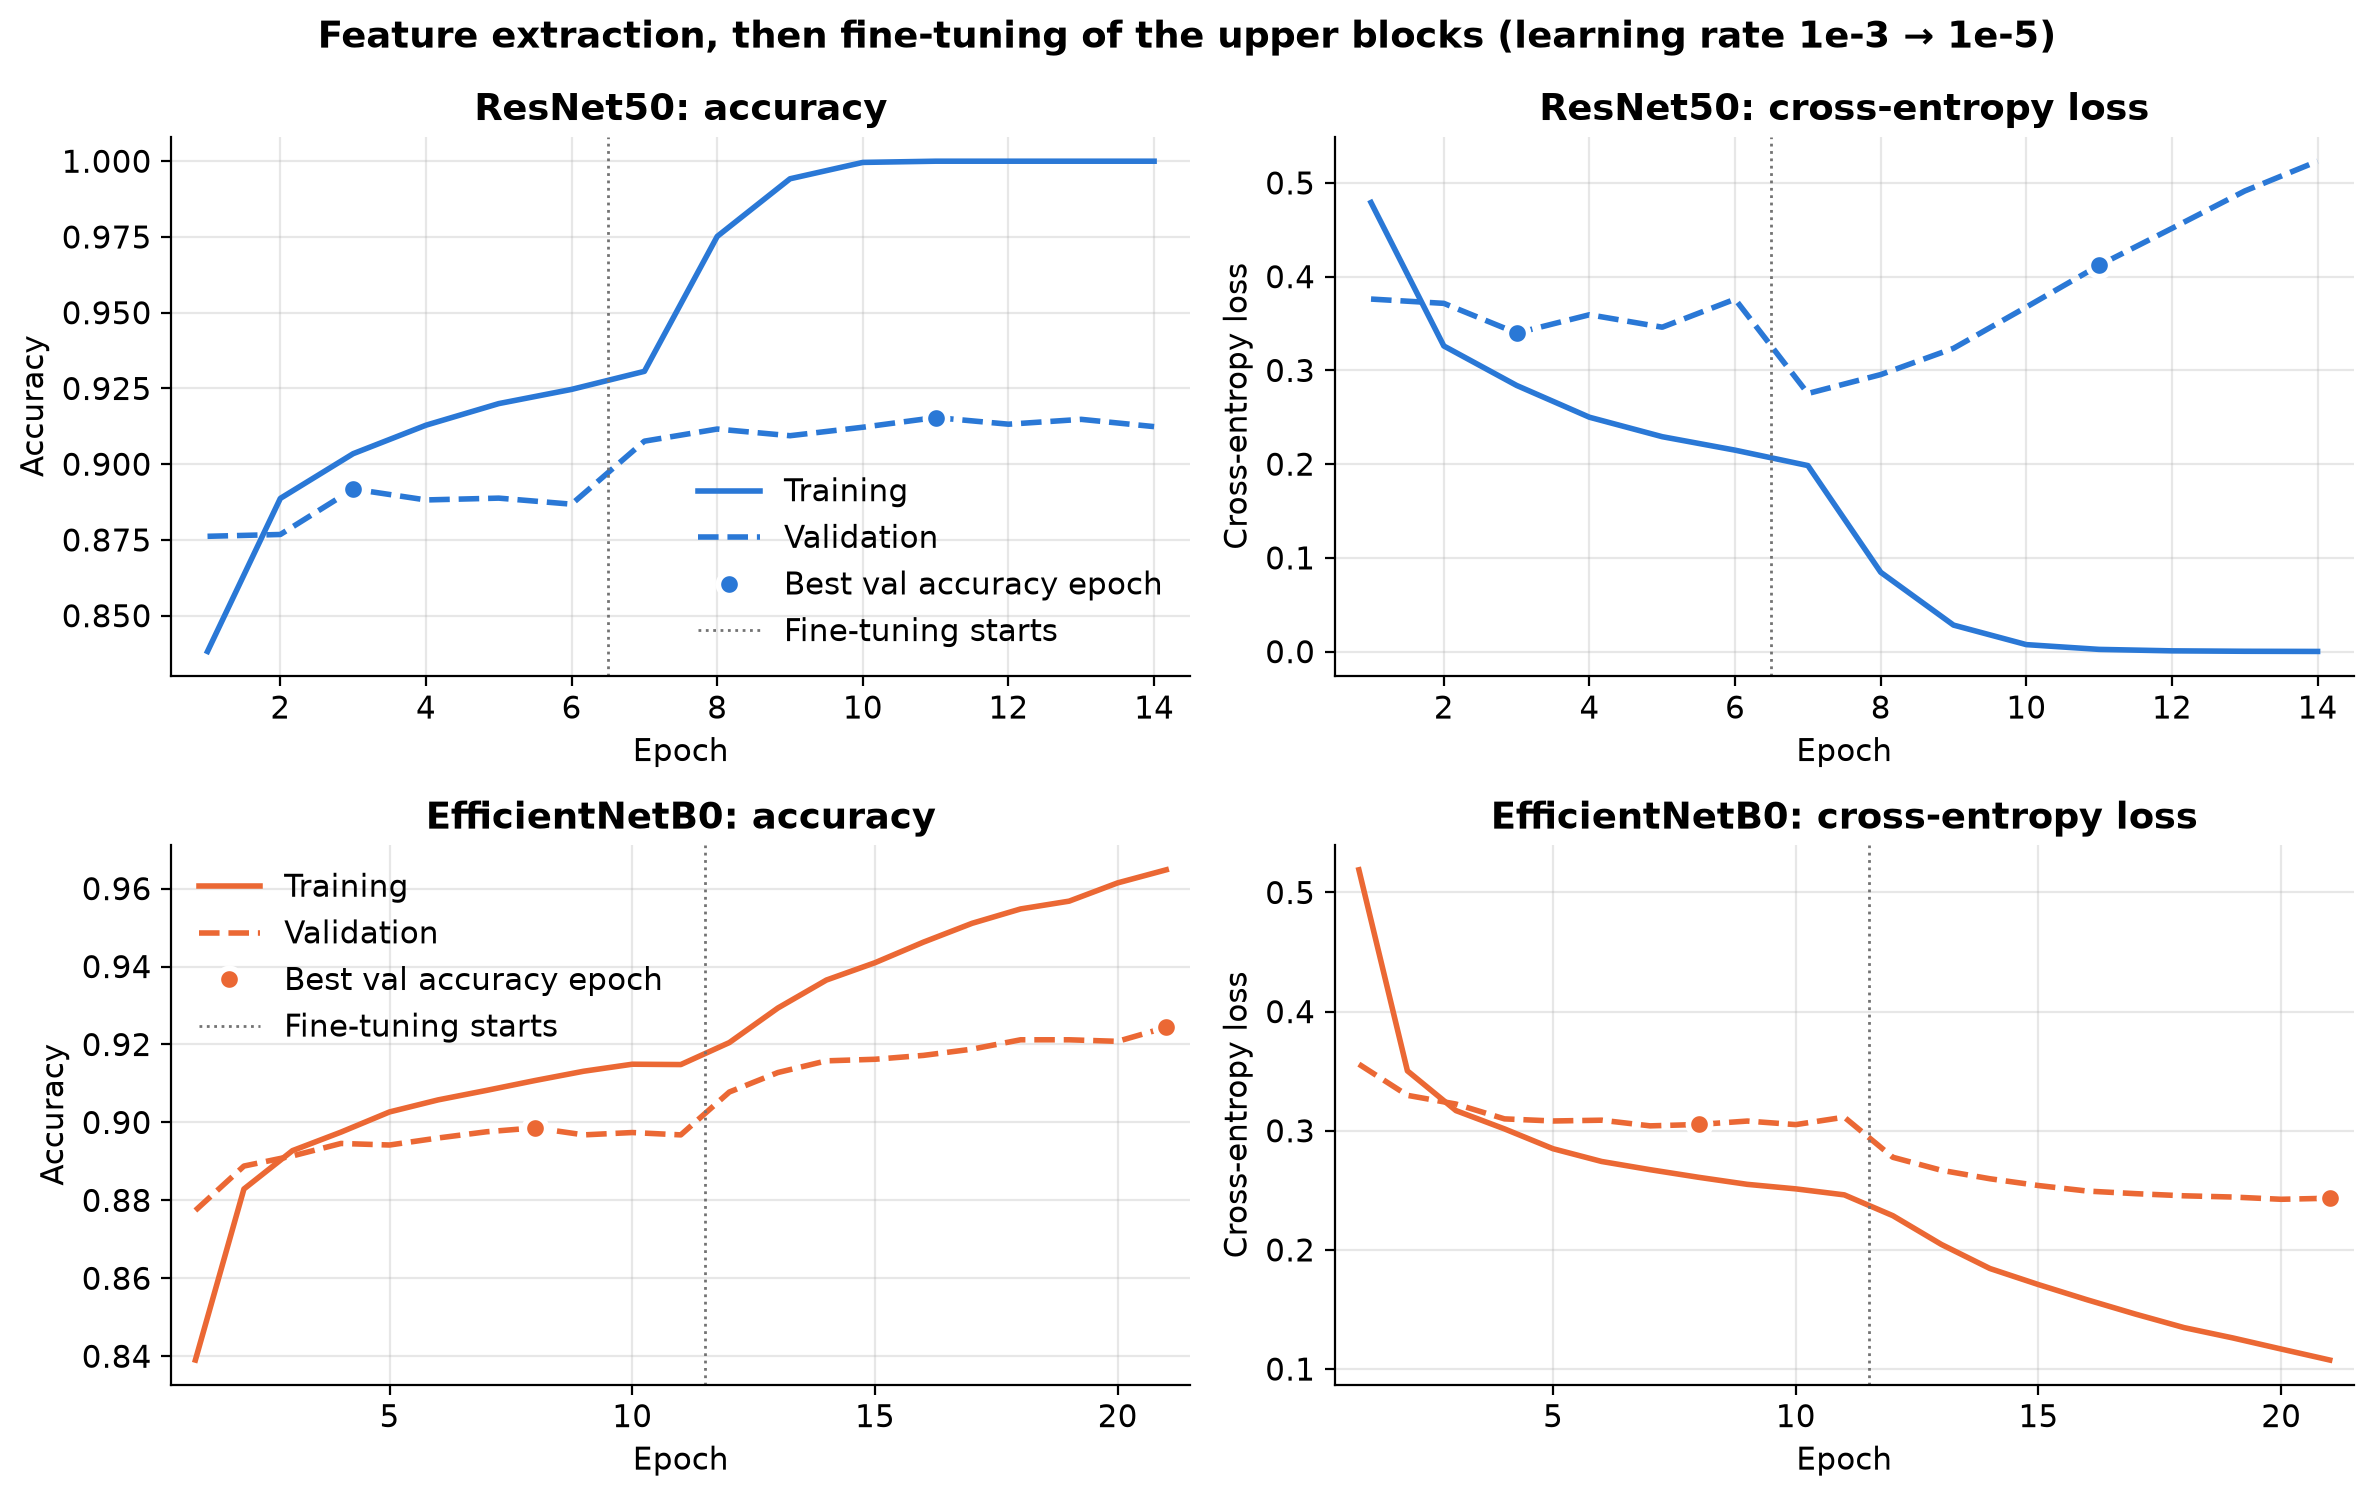

In [17]:
plot_learning_curves(
    {name: [fe_results[name], ft_results[name]] for name in models},
    "Feature extraction, then fine-tuning of the upper blocks (learning rate 1e-3 → 1e-5)",
)

### Before and after fine-tuning

In [18]:
def before_after(name: str) -> pd.DataFrame:
    """Feature extraction vs fine-tuning for one architecture, with the change."""
    fe, ft = summarize(fe_results[name]), summarize(ft_results[name])
    rows = [
        "Best val accuracy", "Val loss at best", "Lowest val loss", "Train accuracy at best",
        "Gap (train − val accuracy)", "Trainable params", "Training time (s)", "Median epoch time (s)",
    ]
    table = pd.DataFrame({"Feature extraction": fe, "Fine-tuning": ft}).loc[rows].astype(float)
    table["Change"] = table["Fine-tuning"] - table["Feature extraction"]
    table.loc["Training time (s)", "Change"] = np.nan  # the fine-tuning column is already the added time
    return table


STAGES = ["Feature extraction", "Fine-tuning"]
ACCURACY_ROWS = ["Best val accuracy", "Train accuracy at best", "Gap (train − val accuracy)"]
LOSS_ROWS = ["Val loss at best", "Lowest val loss"]
TIME_ROWS = ["Training time (s)", "Median epoch time (s)"]

for name in models:
    display(
        before_after(name)
        .style.format("{:.2%}", subset=pd.IndexSlice[ACCURACY_ROWS, STAGES])
        .format(lambda value: f"{100 * value:+.2f} pp", subset=pd.IndexSlice[ACCURACY_ROWS, ["Change"]])
        .format("{:.4f}", subset=pd.IndexSlice[LOSS_ROWS, STAGES])
        .format("{:+.4f}", subset=pd.IndexSlice[LOSS_ROWS, ["Change"]])
        .format("{:,.0f}", subset=pd.IndexSlice[["Trainable params"], STAGES])
        .format("{:+,.0f}", subset=pd.IndexSlice[["Trainable params"], ["Change"]])
        .format("{:.1f}", subset=pd.IndexSlice[TIME_ROWS, STAGES])
        .format("{:+.1f}", subset=pd.IndexSlice[TIME_ROWS, ["Change"]], na_rep="—")
        .set_caption(f"{name} (Change: percentage points for accuracy rows)")
    )

,Feature extraction,Fine-tuning,Change
Best val accuracy,89.18%,91.54%,+2.36 pp
Val loss at best,0.3399,0.4121,+0.0723
Lowest val loss,0.3399,0.2754,-0.0645
Train accuracy at best,90.35%,100.00%,+9.65 pp
Gap (train − val accuracy),1.17%,8.46%,+7.29 pp
Trainable params,"20,490","14,973,962","+14,953,472"
Training time (s),68.7,111.4,—
Median epoch time (s),8.7,11.6,+2.9


,Feature extraction,Fine-tuning,Change
Best val accuracy,89.86%,92.44%,+2.58 pp
Val loss at best,0.3053,0.2434,-0.0619
Lowest val loss,0.3041,0.2425,-0.0616
Train accuracy at best,91.08%,96.48%,+5.41 pp
Gap (train − val accuracy),1.22%,4.04%,+2.83 pp
Trainable params,"12,810","2,300,314","+2,287,504"
Training time (s),115.3,119.9,—
Median epoch time (s),8.1,9.1,+1.0


### Effect of fine-tuning

**ResNet50: accuracy improved, generalization weakened.** Best validation accuracy rose 2.36 pp to 91.54% (118 images), about 4 standard errors of the difference. Validation loss bottomed at 0.2754 in the first fine-tuning epoch, then rose in all seven later epochs to 0.5232. At the best epoch it was 0.4121, 0.0723 above feature extraction. Training accuracy reached 100.00% by epoch 11, and the gap grew from 1.17 to 8.46 pp. *Hypothesis:* the rising loss at flat accuracy reflects increasingly overconfident mistakes after memorization. Unfreezing 14,953,472 parameters raised the median epoch from 8.7 to 11.6 s, and the stage added 111 s over 8 epochs.

**EfficientNetB0: improved.** Best validation accuracy rose 2.58 pp to 92.44%, about 4.5 standard errors. Validation loss fell from 0.3053 to 0.2434 and rose only in the last epoch. Training accuracy reached 96.48%, and the gap grew from 1.22 to 4.04 pp. The best epoch was the last allowed, so the epoch budget, not early stopping, ended the stage. Unfreezing 2,287,504 parameters raised the median epoch from 8.1 to 9.1 s, and the stage added 120 s over 10 epochs.

**Why the two differ.** Fine-tuning helped both about equally on accuracy: the gains differ by 0.22 pp. Overfitting is what differs. ResNet50 unfroze 6.5 times as many parameters and memorized the training set within five fine-tuning epochs. *Hypothesis:* Adam moves each weight by about the learning rate per step, so at the same 1e-5 rate ResNet50's larger `conv5` stage changes more weights, and its function more, per step. The two stages also differ in depth and design, so this is untested.

## Step 5 — Compare the architectures

One reporting rule for all four rows (see Overview): each stage at its best-validation-accuracy epoch. The fine-tuned model's *cumulative* time also counts the feature-extraction stage it builds on.

In [19]:
all_results = [result for name in models for result in (fe_results[name], ft_results[name])]
rows = pd.DataFrame([summarize(result) for result in all_results])
rows["Cumulative time (s)"] = rows.groupby("Architecture")["Training time (s)"].cumsum()
fe_accuracy = rows[rows["Stage"] == "Feature extraction"].set_index("Architecture")["Best val accuracy"]


def key_observation(row: pd.Series) -> str:
    """A factual one-line note derived from the row's own numbers."""
    stopping = "early-stopped" if row["Epochs run"] < row["Max epochs"] else "used every epoch"
    note = f"best at epoch {row['Best epoch']}, {stopping}; gap {100 * row['Gap (train − val accuracy)']:+.1f} pp"
    if row["Stage"] == "Fine-tuning":
        change = row["Best val accuracy"] - fe_accuracy[row["Architecture"]]
        note = f"{100 * change:+.2f} pp val accuracy vs feature extraction; {note}"
    return note


rows["Key observation"] = rows.apply(key_observation, axis=1)

table_2 = rows[["Architecture", "Stage", "Trainable params", "Best val accuracy", "Training time (s)", "Key observation"]]
table_2 = table_2.rename(columns={"Stage": "Training stage", "Best val accuracy": "Best validation accuracy"})
table_2.style.format(
    {"Trainable params": "{:,}", "Best validation accuracy": "{:.2%}", "Training time (s)": "{:,.0f}"}
).hide(axis="index").set_caption("Table 2: summary comparison")

Architecture,Training stage,Trainable params,Best validation accuracy,Training time (s),Key observation
ResNet50,Feature extraction,"20,490",89.18%,69,"best at epoch 3, early-stopped; gap +1.2 pp"
ResNet50,Fine-tuning,"14,973,962",91.54%,111,"+2.36 pp val accuracy vs feature extraction; best at epoch 11, early-stopped; gap +8.5 pp"
EfficientNetB0,Feature extraction,"12,810",89.86%,115,"best at epoch 8, early-stopped; gap +1.2 pp"
EfficientNetB0,Fine-tuning,"2,300,314",92.44%,120,"+2.58 pp val accuracy vs feature extraction; best at epoch 21, used every epoch; gap +4.0 pp"


The fuller view behind Table 2: gaps, validation loss, stability (how many epochs validation loss rose), and cost.

In [20]:
detail_columns = [
    "Architecture", "Stage", "Best val accuracy", "Val loss at best", "Lowest val loss",
    "Gap (train − val accuracy)", "Val-loss increases", "Epochs run", "Total params",
    "Trainable params", "Median epoch time (s)", "Training time (s)", "Cumulative time (s)",
]
rows[detail_columns].set_index(["Architecture", "Stage"]).style.format(
    {column: fmt for column, fmt in METRIC_FORMATS.items() if column in detail_columns}
)

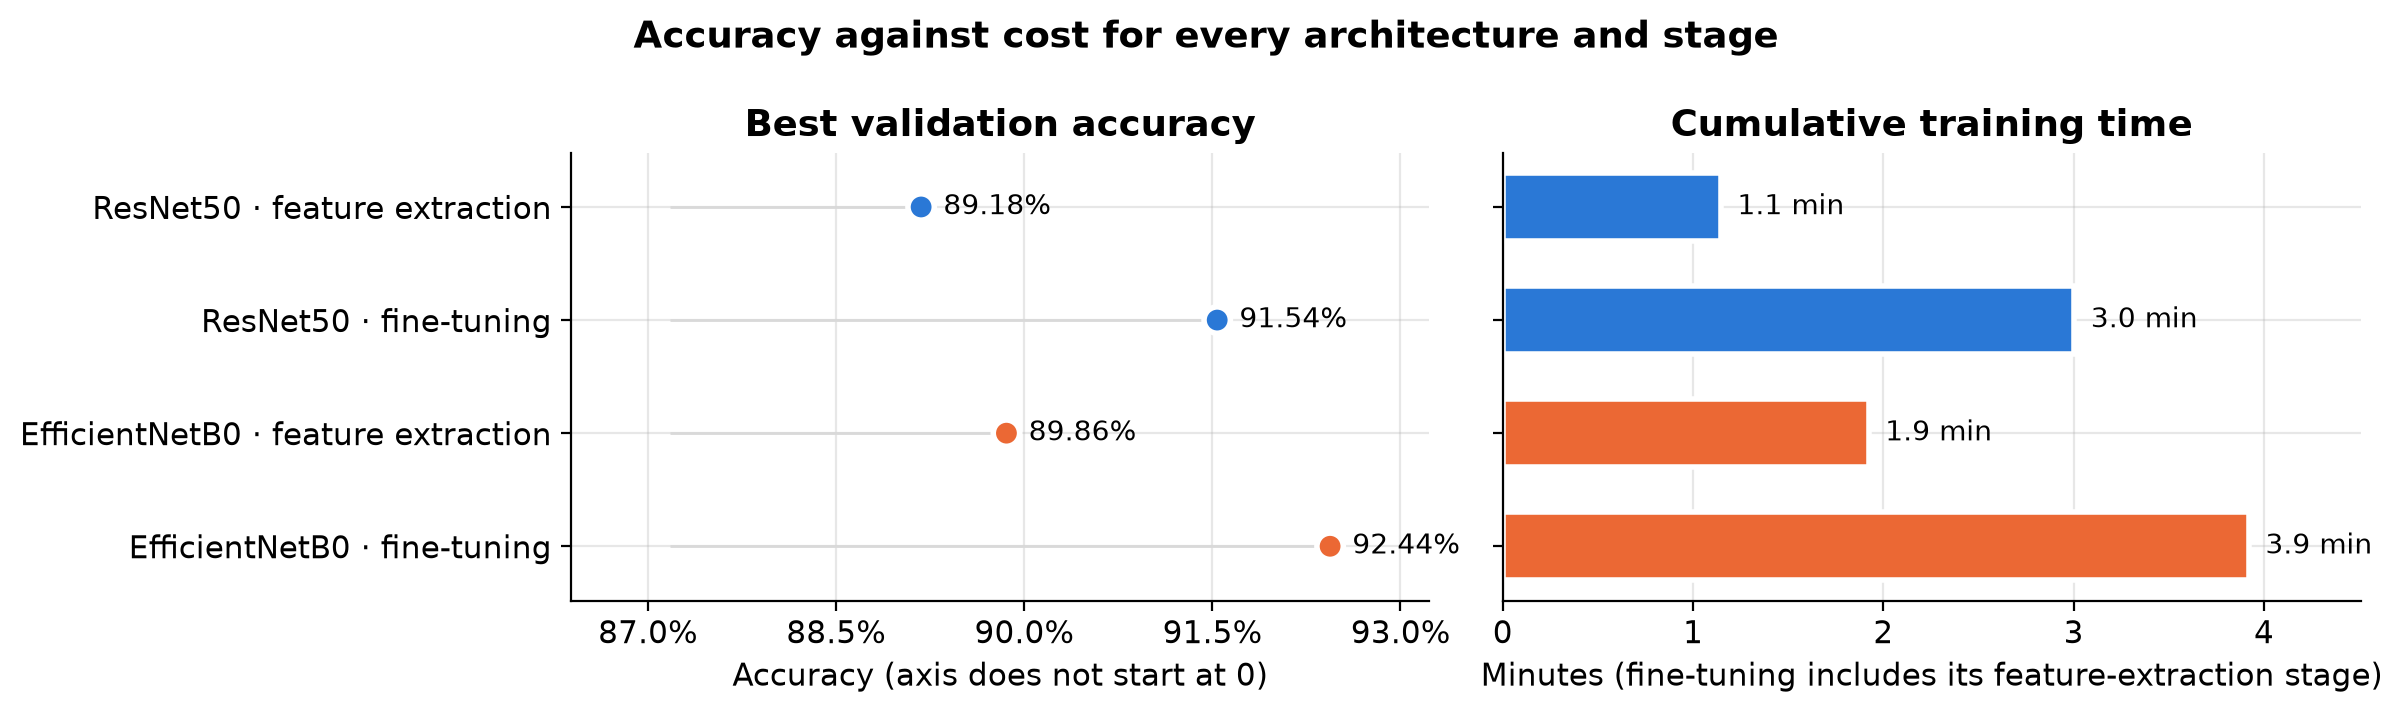

In [21]:
labels = [f"{row.Architecture} · {row.Stage.lower()}" for row in rows.itertuples()]
colors = [COLORS[name] for name in rows["Architecture"]]
positions = np.arange(len(rows))[::-1]
accuracy, minutes = rows["Best val accuracy"], rows["Cumulative time (s)"] / 60

fig, (ax_accuracy, ax_time) = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
ax_accuracy.hlines(positions, accuracy.min() - 0.02, accuracy, color="0.85", lw=1)
ax_accuracy.scatter(accuracy, positions, s=90, c=colors, edgecolors="white", linewidths=2, zorder=3)
for y, value in zip(positions, accuracy):
    ax_accuracy.annotate(f"{value:.2%}", (value, y), xytext=(8, 0), textcoords="offset points", va="center", fontsize=10)
ax_accuracy.set(
    title="Best validation accuracy", xlabel="Accuracy (axis does not start at 0)",
    yticks=positions, yticklabels=labels,
)
ax_accuracy.xaxis.set_major_locator(MaxNLocator(5))
ax_accuracy.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
ax_accuracy.margins(x=0.15)

ax_time.barh(positions, minutes, color=colors, height=0.6, edgecolor="white", linewidth=2)
for y, value in zip(positions, minutes):
    ax_time.annotate(f"{value:.1f} min", (value, y), xytext=(6, 0), textcoords="offset points", va="center", fontsize=10)
ax_time.set(title="Cumulative training time", xlabel="Minutes (fine-tuning includes its feature-extraction stage)")
ax_time.margins(x=0.15)
fig.suptitle("Accuracy against cost for every architecture and stage", fontweight="bold")
fig.tight_layout()
plt.show()

### Selecting the final model (validation evidence only)

The rule, fixed before looking at any test result: the highest **best validation accuracy** wins. Exact ties go to the lower cumulative training time.

In [22]:
ranked = rows.sort_values(["Best val accuracy", "Cumulative time (s)"], ascending=[False, True])
final_row, runner_up = ranked.iloc[0], ranked.iloc[1]
print(
    f"Final model: {final_row['Architecture']}, {final_row['Stage'].lower()}: "
    f"best val accuracy {final_row['Best val accuracy']:.2%} at epoch {final_row['Best epoch']}"
)
print(
    f"Runner-up:   {runner_up['Architecture']}, {runner_up['Stage'].lower()}: "
    f"{runner_up['Best val accuracy']:.2%} "
    f"(margin {100 * (final_row['Best val accuracy'] - runner_up['Best val accuracy']):.2f} pp)"
)

Final model: EfficientNetB0, fine-tuning: best val accuracy 92.44% at epoch 21
Runner-up:   ResNet50, fine-tuning: 91.54% (margin 0.90 pp)


### Comparison and justification

**Validation performance.** Fine-tuned EfficientNetB0 leads on accuracy (92.44%) and validation loss (0.2434). Fine-tuned ResNet50 is second on accuracy (91.54%) but has the highest validation loss of the four rows (0.4121).

**Gaps.** With frozen bases, both gaps were near 1.2 pp at the best epoch. Fine-tuning widened them to 8.46 pp for ResNet50 and 4.04 pp for EfficientNetB0.

**Effect of fine-tuning.** The accuracy gains are similar (+2.36 and +2.58 pp), but validation loss moved in opposite directions (+0.0723 and −0.0619).

**Parameter efficiency.** EfficientNetB0 is more accurate at both stages with 5.8 times fewer parameters (4.06 M against 23.61 M). Fine-tuned, it trains 2.30 M parameters against 14.97 M.

**Computational cost.** EfficientNetB0 is faster per image (6,426 against 4,793 images/s in Step 2) and per epoch: 8.1 against 8.7 s in feature extraction and 9.1 against 11.6 s in fine-tuning. Cumulative time still favors ResNet50 (180 s against 235 s), because early stopping ended its stages sooner (14 epochs against 21). Single timings on a shared GPU node are approximate.

**Stability.** Validation loss rose in 2 and 7 epochs for ResNet50 (feature extraction, fine-tuning) and in 4 and 1 for EfficientNetB0. Fine-tuned ResNet50's rose in every epoch after the first, while its validation accuracy stayed within 91.22–91.54% from epoch 10. EfficientNetB0's fine-tuning curves are the smoothest.

**Final model: EfficientNetB0 after fine-tuning**, at 92.44% validation accuracy (epoch 21), against 91.54% for fine-tuned ResNet50. The 0.90 pp margin is 45 of 5,000 images. With standard errors of 0.37 and 0.39 pp, it is about 1.7 standard errors of the difference, treating the estimates as independent; a paired test on the shared images would be tighter. On its own the margin is suggestive, not conclusive, and each model ran once. The choice does not hinge on the epoch-21 peak: EfficientNetB0 exceeded 91.54% in every epoch from 14 to 21, and its lower validation loss and narrower gap point the same way.

## Step 6 — Evaluate the final model

The final model's saved best-validation weights are reloaded (they belong to either the feature-extraction or the fine-tuning stage). The model then makes **one pass over the test set**. Test loss and accuracy are computed from those predictions, and every diagnostic below reuses them. Nothing here feeds back into model selection.

In [23]:
final_name, final_stage = final_row["Architecture"], final_row["Stage"]
final_result = {"Feature extraction": fe_results, "Fine-tuning": ft_results}[final_stage][final_name]
final_model = models[final_name]
with warnings.catch_warnings():  # the file also holds that stage's optimizer state, not needed to evaluate
    warnings.filterwarnings("ignore", message="Skipping variable loading for optimizer")
    final_model.load_weights(final_result.weights_path)

final_model.compile(loss="sparse_categorical_crossentropy", metrics=["accuracy"])  # evaluation only
_, reloaded_val_accuracy = final_model.evaluate(datasets[final_name]["val"], verbose=0)
print(
    f"Reloaded weights: val accuracy {reloaded_val_accuracy:.4f} "
    f"(recorded best {final_row['Best val accuracy']:.4f})"
)

Reloaded weights: val accuracy 0.9244 (recorded best 0.9244)


In [24]:
test_probabilities = final_model.predict(datasets[final_name]["test"], verbose=0)  # the single test pass
test_predictions = test_probabilities.argmax(axis=1)
test_confidence = test_probabilities.max(axis=1)
test_accuracy = float(np.mean(test_predictions == y_test))
test_loss = float(np.mean(keras.losses.sparse_categorical_crossentropy(y_test, test_probabilities)))

if final_stage == "Feature extraction":
    training = f"frozen base, Adam {FE_LEARNING_RATE:g}"
else:
    training = (
        f"{unfreeze_reports[final_name]['Blocks unfrozen']} unfrozen (BN frozen), "
        f"Adam {FT_LEARNING_RATE:g} after feature extraction at {FE_LEARNING_RATE:g}"
    )
configuration = (
    f"{final_name} at {IMG_SIZE}×{IMG_SIZE} with its own preprocessing → GAP → Dense(10, softmax); "
    f"{training}; batch {BATCH_SIZE}; weights from epoch {final_row['Best epoch']}"
)
final_summary = pd.Series(
    {
        "Final architecture": final_name,
        "Training stage": final_stage,
        "Final model configuration": configuration,
        "Best validation accuracy": f"{final_row['Best val accuracy']:.2%}",
        "Test accuracy": f"{test_accuracy:.2%}",
        "Test loss": f"{test_loss:.4f}",
        "Validation − test accuracy": f"{100 * (final_row['Best val accuracy'] - test_accuracy):+.2f} pp",
        "Total parameters": f"{final_result.total_params:,}",
        "Trainable parameters": f"{final_result.trainable_params:,}",
    },
    name="Value",
).to_frame()
with pd.option_context("display.max_colwidth", None):  # show the full configuration string
    display(final_summary)

,Value
Final architecture,EfficientNetB0
Training stage,Fine-tuning
Final model configuration,"EfficientNetB0 at 128×128 with its own preprocessing → GAP → Dense(10, softmax); block6c, block6d, block7a, top unfrozen (BN frozen), Adam 1e-05 after feature extraction at 0.001; batch 64; weights from epoch 21"
Best validation accuracy,92.44%
Test accuracy,91.96%
Test loss,0.2532
Validation − test accuracy,+0.48 pp
Total parameters,"4,062,381"
Trainable parameters,"2,300,314"


### Confusion matrix

Rows are the true class and columns the predicted class. Cell text is the image count, and cell shade is the share of the true class (row-normalized), so the diagonal reads as per-class recall.

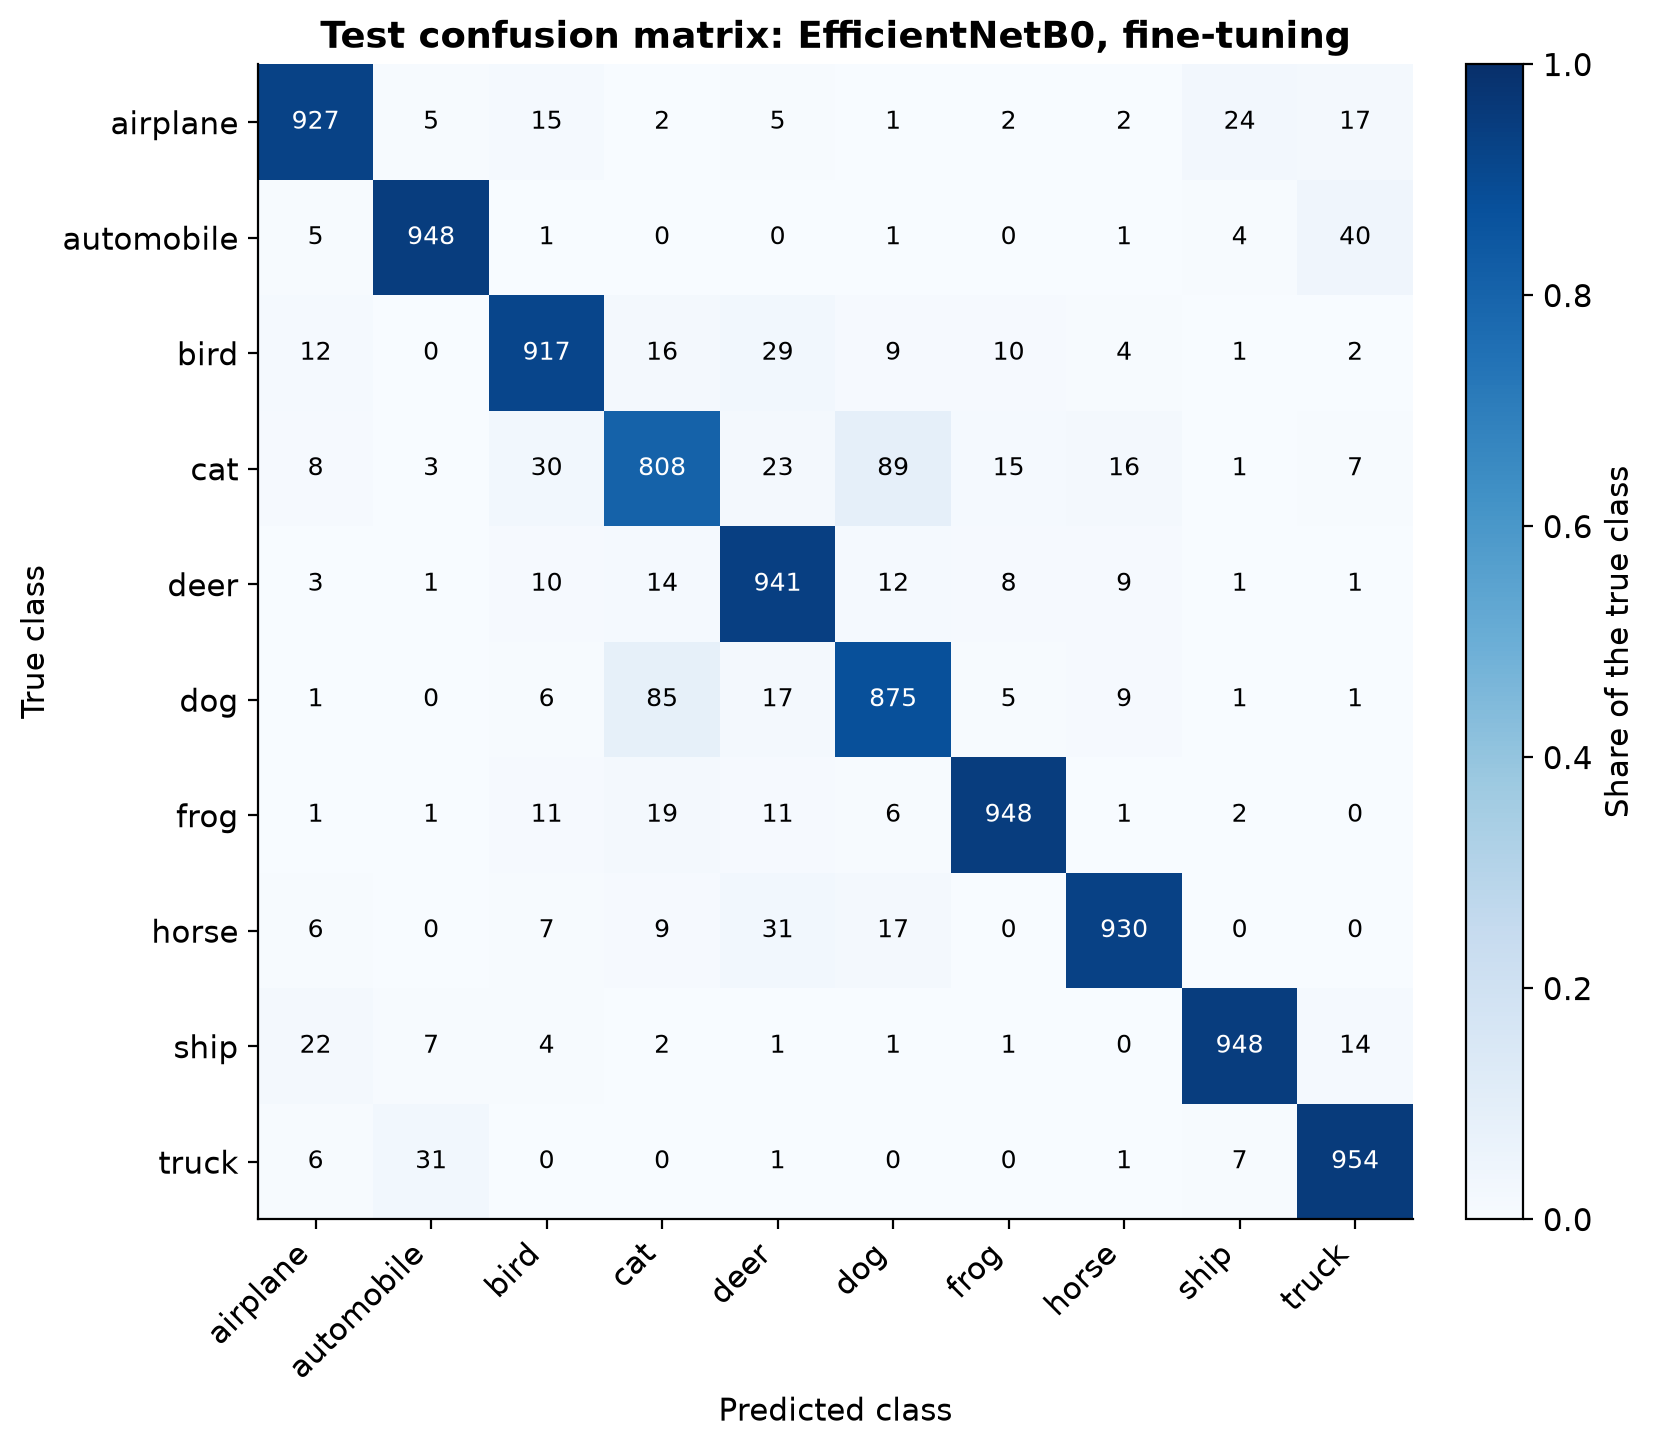

In [25]:
matrix = confusion_matrix(y_test, test_predictions, labels=range(NUM_CLASSES))
row_share = matrix / matrix.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(8.5, 7.5))
image = ax.imshow(row_share, cmap="Blues", vmin=0, vmax=1)
for true in range(NUM_CLASSES):
    for predicted in range(NUM_CLASSES):
        ax.text(
            predicted, true, matrix[true, predicted], ha="center", va="center", fontsize=9,
            color="white" if row_share[true, predicted] > 0.5 else "black",
        )
ax.set(
    xticks=range(NUM_CLASSES), yticks=range(NUM_CLASSES),
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    xlabel="Predicted class", ylabel="True class",
    title=f"Test confusion matrix: {final_name}, {final_stage.lower()}",
)
ax.grid(False)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="Share of the true class")
plt.show()

### Per-class precision, recall, and F1-score

Sorted from the weakest class (lowest F1) to the strongest.

In [26]:
report = pd.DataFrame(
    classification_report(y_test, test_predictions, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
).T
report["support"] = report["support"].astype(int)
per_class = report.loc[CLASS_NAMES].sort_values("f1-score")
display(per_class)
report.loc[["macro avg", "weighted avg"]]

,precision,recall,f1-score,support
cat,0.8461,0.808,0.8266,1000
dog,0.8655,0.875,0.8702,1000
deer,0.8886,0.941,0.9140,1000
bird,0.9161,0.917,0.9165,1000
airplane,0.9354,0.927,0.9312,1000
truck,0.9208,0.954,0.9371,1000
horse,0.9558,0.930,0.9427,1000
automobile,0.9518,0.948,0.9499,1000
frog,0.9585,0.948,0.9532,1000
ship,0.9585,0.948,0.9532,1000


,precision,recall,f1-score,support
macro avg,0.9197,0.9196,0.9195,10000
weighted avg,0.9197,0.9196,0.9195,10000


### Most frequently confused classes

Directed errors (true → predicted), then the same errors combined per unordered class pair.

In [27]:
errors = pd.DataFrame(
    [
        {
            "True": CLASS_NAMES[true],
            "Predicted": CLASS_NAMES[predicted],
            "Images": matrix[true, predicted],
            "Share of true class (%)": 100 * row_share[true, predicted],
        }
        for true in range(NUM_CLASSES)
        for predicted in range(NUM_CLASSES)
        if true != predicted
    ]
).sort_values("Images", ascending=False, ignore_index=True)
display(errors.head(10))

errors["Pair"] = [" ↔ ".join(sorted(pair)) for pair in zip(errors["True"], errors["Predicted"])]
pairs = errors.groupby("Pair")["Images"].sum().sort_values(ascending=False)
pairs.head(5).to_frame("Images (both directions)")

,True,Predicted,Images,Share of true class (%)
0,cat,dog,89,8.9
1,dog,cat,85,8.5
2,automobile,truck,40,4.0
3,truck,automobile,31,3.1
4,horse,deer,31,3.1
5,cat,bird,30,3.0
6,bird,deer,29,2.9
7,airplane,ship,24,2.4
8,cat,deer,23,2.3
9,ship,airplane,22,2.2


,Images (both directions)
Pair,
cat ↔ dog,174
automobile ↔ truck,71
bird ↔ cat,46
airplane ↔ ship,46
deer ↔ horse,40


### Examples of correct and incorrect predictions

Shown at the native 32 × 32 resolution, which is all the information the model has. Top: the most confident correct predictions. Bottom: the most confident mistakes, the most informative errors.

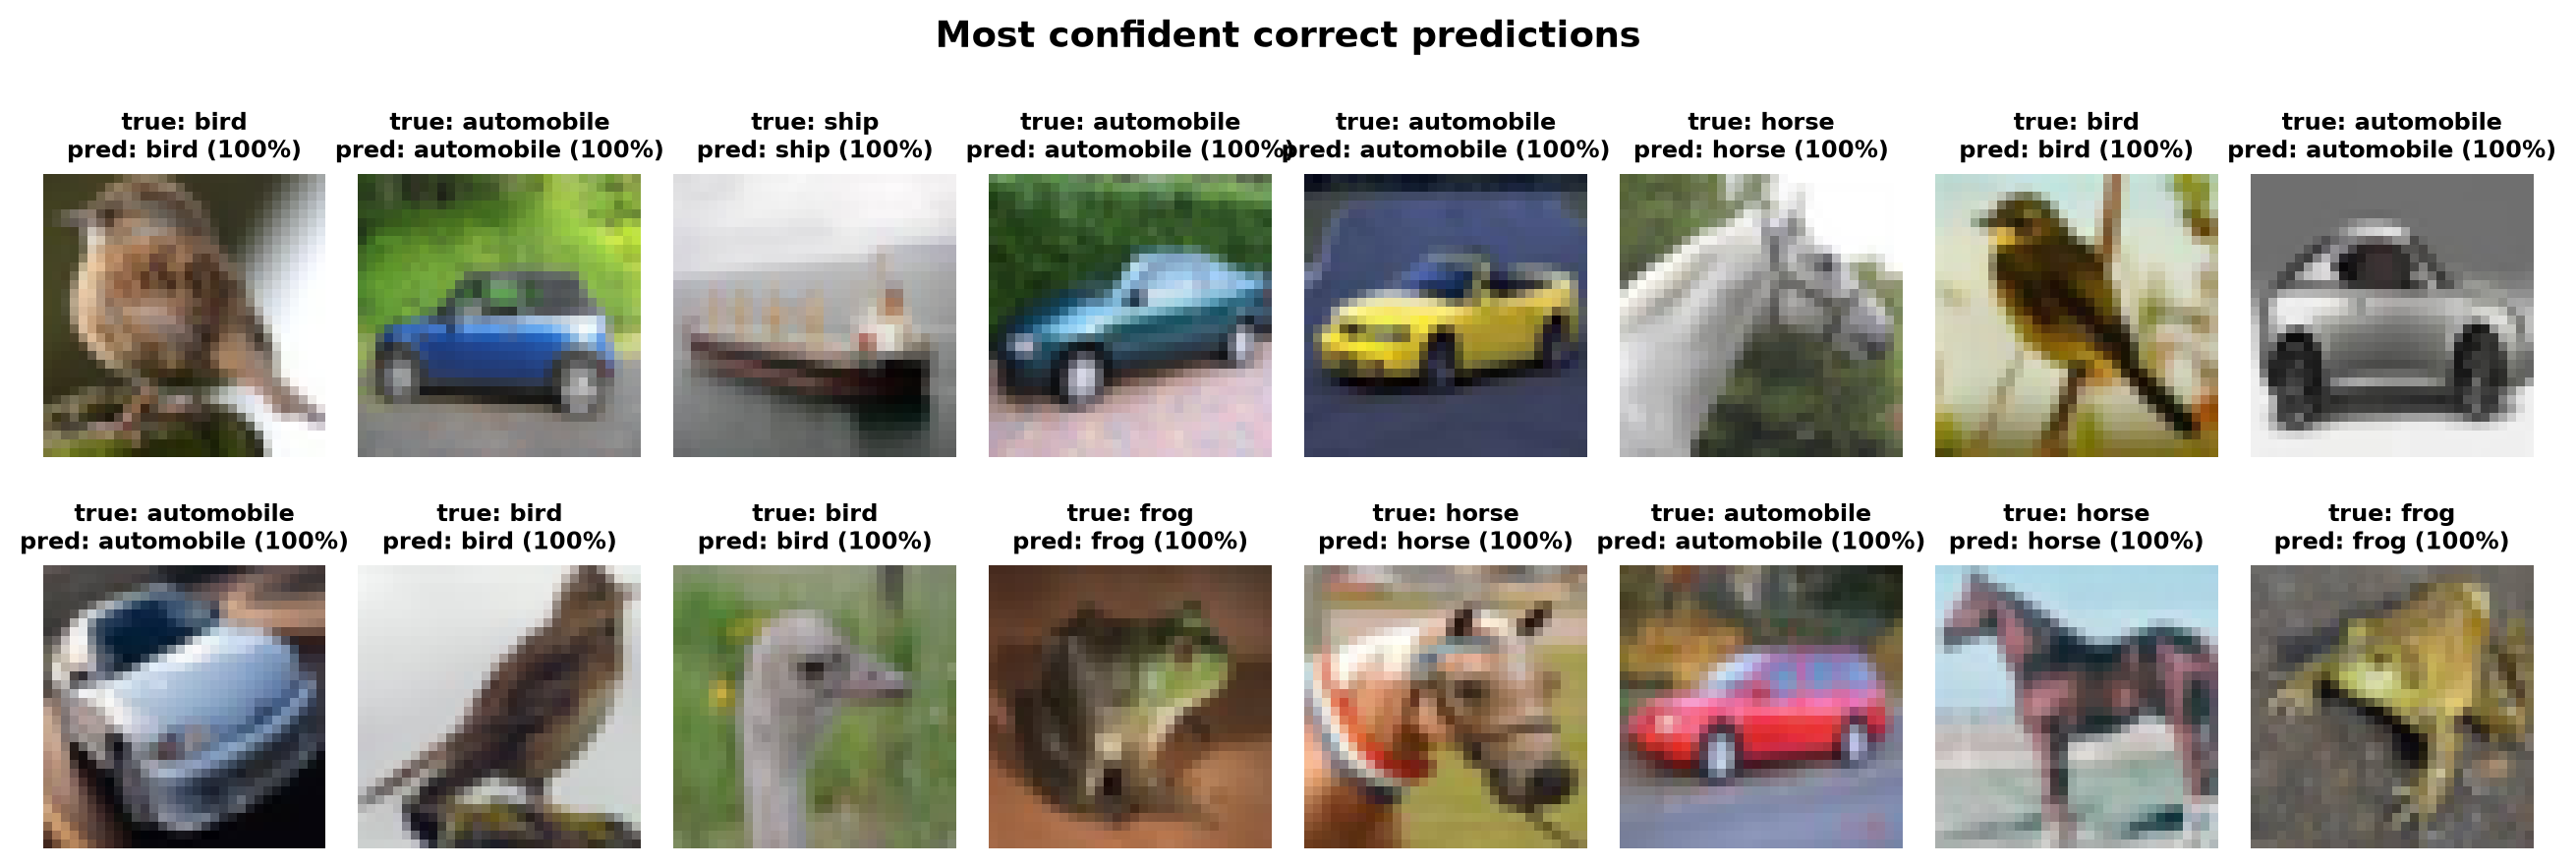

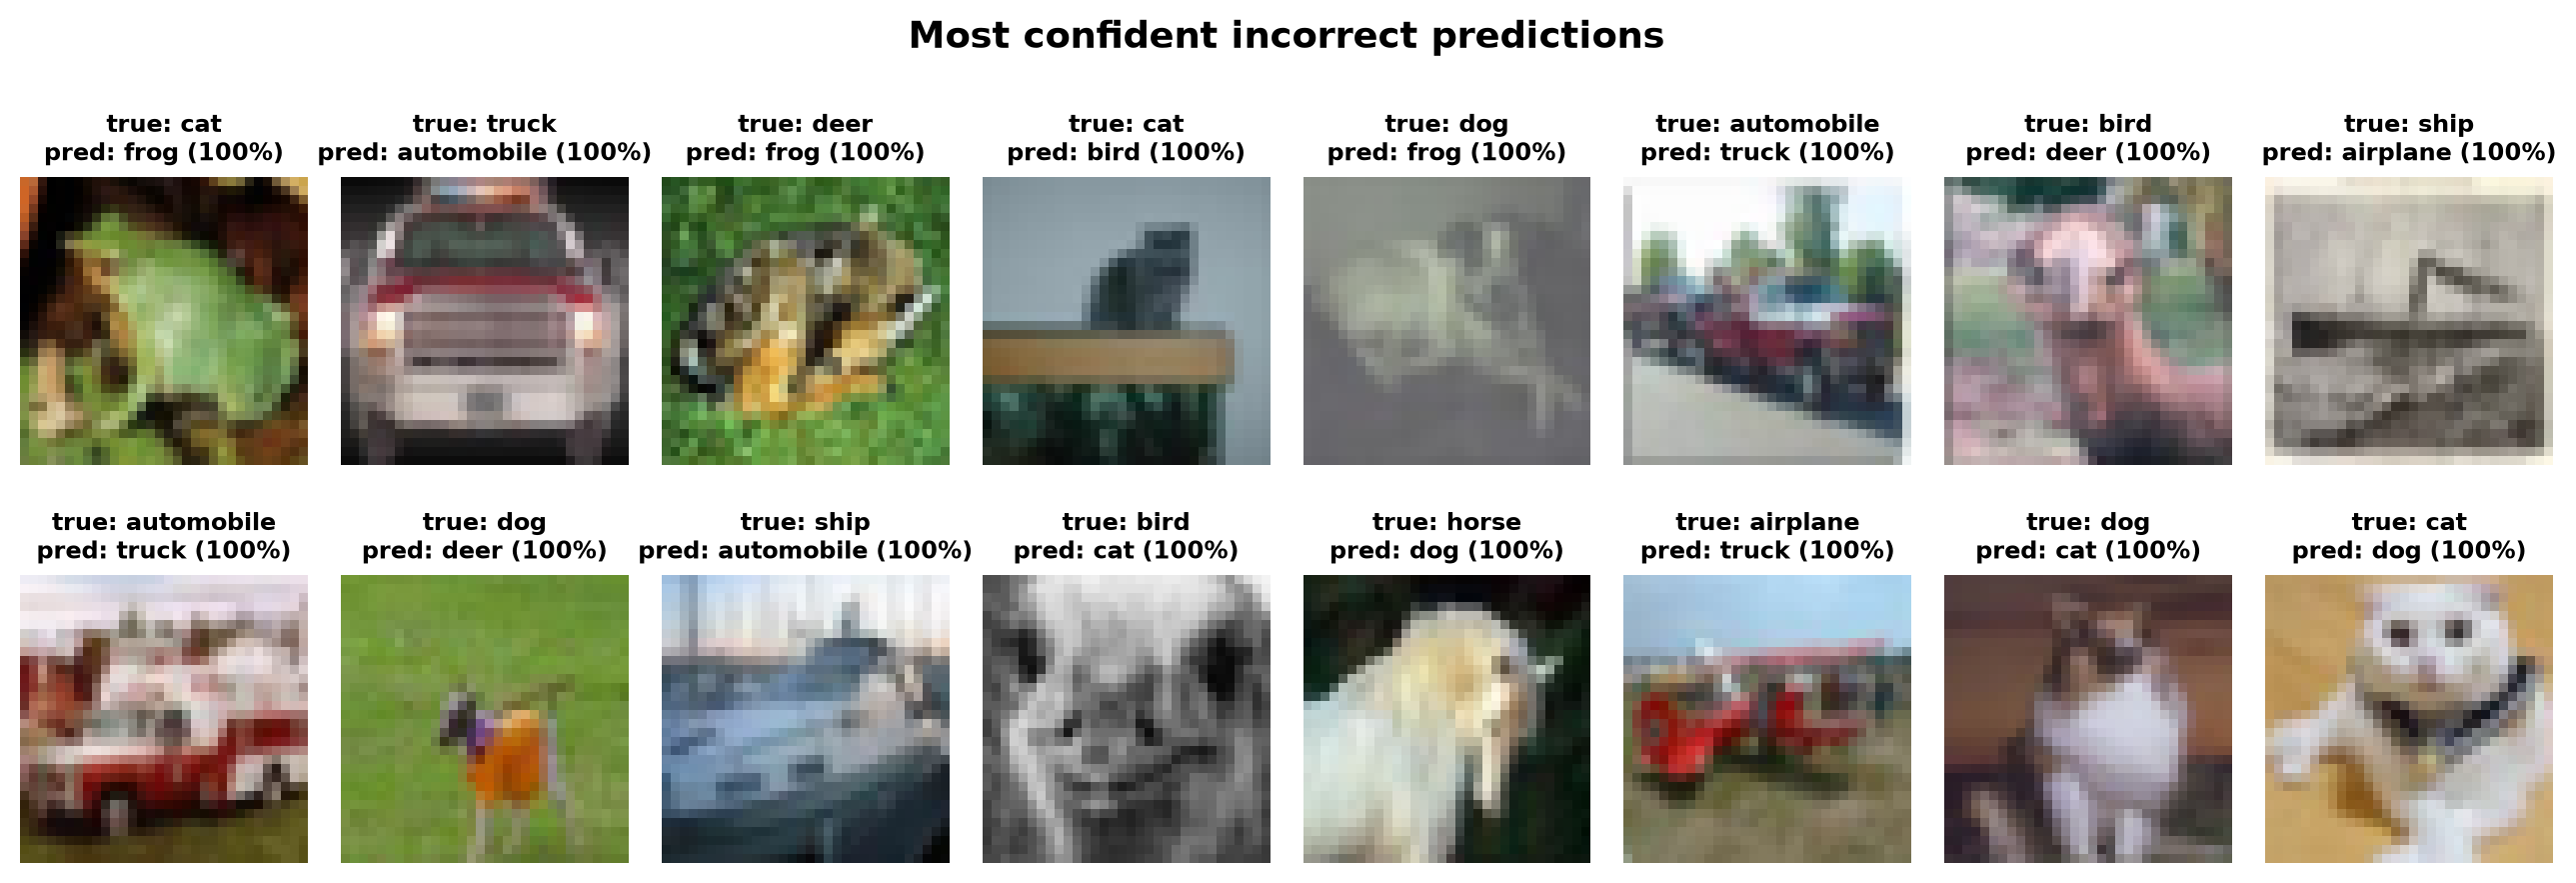

Mean confidence: correct 96.68%, incorrect 73.67%


In [28]:
def show_predictions(indices: np.ndarray, title: str) -> None:
    """Test images with their true label, predicted label, and predicted-class probability."""
    fig, axes = plt.subplots(2, 8, figsize=(13, 4.8))
    for ax, index in zip(axes.ravel(), indices):
        ax.imshow(x_test[index])
        ax.axis("off")
        ax.set_title(
            f"true: {CLASS_NAMES[y_test[index]]}\npred: {CLASS_NAMES[test_predictions[index]]} "
            f"({test_confidence[index]:.0%})",
            fontsize=8.5,
        )
    fig.suptitle(title, fontweight="bold")
    fig.tight_layout()
    plt.show()


correct = np.flatnonzero(test_predictions == y_test)
incorrect = np.flatnonzero(test_predictions != y_test)
show_predictions(correct[np.argsort(-test_confidence[correct])][:16], "Most confident correct predictions")
show_predictions(incorrect[np.argsort(-test_confidence[incorrect])][:16], "Most confident incorrect predictions")
print(
    f"Mean confidence: correct {test_confidence[correct].mean():.2%}, "
    f"incorrect {test_confidence[incorrect].mean():.2%}"
)

### What the diagnostics show beyond overall accuracy

**Weakest classes.** Cat is the outlier: recall 80.80% and precision 84.61%, 11.16 and 7.36 pp below the macro averages. Dog follows (87.50% and 86.55%). Deer has high recall (94.10%) but low precision (88.86%): 111 of its 118 false positives are other animals.

**Dominant confusions.** Cat ↔ dog accounts for 174 of the 804 test errors (21.6%) and is symmetric (89 against 85). Automobile ↔ truck (71) is nearly symmetric (40 against 31). Bird ↔ cat and airplane ↔ ship tie next at 46. The clearest one-sided errors flow into deer: horse → deer 31 against 9, and bird → deer 29 against 10.

**Semantic closeness.** All five most confused pairs join two animals or two vehicles, and only 94 errors (11.7%) cross between the groups. Errors that follow class similarity argue against a pipeline fault. *Hypothesis:* the upsampled 32 × 32 inputs lack the fine detail that separates similar classes; this was not tested.

**Confident mistakes.** The grid shows the 16 most confident errors, a biased sample, and all display 100% after rounding. Recurring patterns are close-ups (a horse's head as dog, two bird faces), washed-out images (a dog as frog, a ship as airplane), animals on grass (a dog as deer), and pickups or vans assigned to the other vehicle class (three cases). *Hypothesis:* one "cat" predicted as frog looks like a green frog, so it may be a labelling error. Across the whole test set, mistakes average 73.67% confidence against 96.68% for correct predictions.

**Validation against test.** Test accuracy (91.96%) is 0.48 pp below validation accuracy, about one standard error of the difference, consistent with the small optimism expected after selecting on validation.

## Final analysis and reflection

The numbers the answers below draw on, gathered in one place.

In [29]:
evidence = rows.set_index(["Architecture", "Stage"])[
    ["Best val accuracy", "Val loss at best", "Gap (train − val accuracy)", "Trainable params",
     "Median epoch time (s)", "Cumulative time (s)", "Val-loss increases"]
]
display(evidence.style.format({column: fmt for column, fmt in METRIC_FORMATS.items() if column in evidence}))
print(f"Final model: {final_name}, {final_stage.lower()}: test accuracy {test_accuracy:.2%}, test loss {test_loss:.4f}")
print(f"Hardest classes (lowest F1): {', '.join(per_class.index[:3])}")
print(f"Most confused pairs: {', '.join(pairs.index[:3])}")

Final model: EfficientNetB0, fine-tuning: test accuracy 91.96%, test loss 0.2532
Hardest classes (lowest F1): cat, dog, deer
Most confused pairs: cat ↔ dog, automobile ↔ truck, bird ↔ cat


### Question 1: How did feature extraction and fine-tuning differ?

**Which parameters were updated.** In feature extraction the optimizer updated only the classification head: the 2,048 × 10 weights and 10 biases of the dense layer for ResNet50 (20,490 parameters), and 1,280 × 10 plus 10 for EfficientNetB0 (12,810). Every pretrained convolution and batch-normalization parameter stayed at its ImageNet value, so each network acted as a fixed feature extractor and training fitted a linear softmax classifier on its pooled features. In fine-tuning, the non-batch-normalization layers of the upper blocks became trainable as well: ResNet50's whole `conv5` stage and EfficientNetB0's `block6c` through `top` (exact counts in the Step 4 table). All batch-normalization layers, including those inside the unfrozen range, kept their scale, shift, and ImageNet statistics, and everything below the cut stayed frozen.

**Effects on training behavior and validation performance.** With the base frozen, both heads converged within a few epochs. ResNet50 peaked at epoch 3 and EfficientNetB0 at epoch 8, and early stopping ended the runs at epochs 6 and 11. Both gaps were about 1.2 pp at the best epoch, consistent with fitting only a linear classifier on fixed features, and validation accuracy settled at 89–90% for both.

Fine-tuning raised best validation accuracy by 2.36 pp for ResNet50 and 2.58 pp for EfficientNetB0, but the two networks behaved differently. ResNet50 fit its training set completely, its validation loss rose in every epoch after the first fine-tuning epoch, and its gap at the best epoch reached 8.46 pp. EfficientNetB0 improved on both validation metrics: its validation loss fell from 0.3053 to 0.2434, its gap grew only to 4.04 pp, and it was still improving when its 10-epoch budget ran out. The backward pass through the unfrozen blocks added 2.9 s to ResNet50's median epoch (8.7 to 11.6 s) and 1.0 s to EfficientNetB0's (8.1 to 9.1 s).

### Question 2: Which architecture and stage gave the best balance, and why?

**Best balance.** EfficientNetB0 after fine-tuning. It has the highest validation accuracy (92.44%) and the lowest validation loss (0.2434), and its gap is under half that of fine-tuned ResNet50 (4.04 against 8.46 pp). It uses 4,062,381 parameters, 2,300,314 of them trainable, and has the cheaper fine-tuning epoch (9.1 s against 11.6 s). Its one cost disadvantage is cumulative time: 235 s against 180 s for fine-tuned ResNet50, from 21 epochs against 14. The cheapest option, ResNet50 feature extraction (69 s), saves about 2.8 minutes but gives up 3.26 pp of validation accuracy. Best balance and best accuracy coincide here, and the single test result (91.96%) stays close to the validation accuracy.

**Factors that may explain the differences.** Capacity has the clearest evidence: ResNet50 unfroze 14,953,472 parameters against 2,287,504 and memorized the training set, while EfficientNetB0 did not. *Hypothesis:* at the same 1e-5 rate, the larger trainable block has enough capacity to fit 45,000 images exactly. With only two models, capacity cannot be separated from the other architectural differences. Feature dimensionality gave ResNet50 no advantage: its 2,048 pooled features scored 89.18% under a linear head, against 89.86% for EfficientNetB0's 1,280. *Hypothesis:* B0's squeeze-and-excitation units, which reweight channels per image, adapt more easily to upsampled CIFAR inputs. Both networks gained over 2 pp from adapting their upper blocks. *Hypothesis:* those blocks hold the most ImageNet-specific features, which is why adapting them helps. Frozen batch normalization did not destabilize early fine-tuning: validation accuracy rose in the first fine-tuning epoch for both (to 90.76% and 90.78%); unfreezing it was not tested. On the L40S, B0's roughly 10× FLOP advantage shrank to 1.34× the inference throughput and a 22% shorter fine-tuning epoch. *Hypothesis:* depthwise convolutions and squeeze-and-excitation are memory-bound (Step 2), so GPU time falls far less than FLOPs.

**Limitations.** Each configuration ran once with one seed, so run-to-run variance is unmeasured, and each validation accuracy carries a standard error of about 0.4 pp. The study used one resolution, one unfreezing depth, one fine-tuning rate and no augmentation. *Hypothesis:* a lower rate or augmentation would help ResNet50 most, since overfitting limited it. EfficientNetB0 hit its 10-epoch fine-tuning limit at its best epoch, so it may not have converged. Timings are single measurements on a shared GPU node.

## References and acknowledgments

- Chollet, F. (n.d.). *Transfer learning & fine-tuning*. Keras. https://keras.io/guides/transfer_learning/
- Chollet, F., et al. (2015). *Keras* [Computer software]. https://keras.io
- Deng, J., Dong, W., Socher, R., Li, L.-J., Li, K., & Fei-Fei, L. (2009). ImageNet: A large-scale hierarchical image database. In *2009 IEEE Conference on Computer Vision and Pattern Recognition* (pp. 248–255). IEEE. https://doi.org/10.1109/CVPR.2009.5206848
- He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for image recognition. In *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 770–778). https://doi.org/10.1109/CVPR.2016.90
- Hu, J., Shen, L., & Sun, G. (2018). Squeeze-and-excitation networks. In *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 7132–7141). https://doi.org/10.1109/CVPR.2018.00745
- Krizhevsky, A. (2009). *Learning multiple layers of features from tiny images* [Technical report]. University of Toronto.
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., & Chen, L.-C. (2018). MobileNetV2: Inverted residuals and linear bottlenecks. In *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 4510–4520). https://doi.org/10.1109/CVPR.2018.00474
- Tan, M., & Le, Q. V. (2019). EfficientNet: Rethinking model scaling for convolutional neural networks. In *Proceedings of the 36th International Conference on Machine Learning* (pp. 6105–6114). PMLR.

**Data and models.** CIFAR-10 is loaded through `tensorflow.keras.datasets.cifar10`. The pretrained ImageNet weights for ResNet50 and EfficientNetB0 come from Keras Applications. The workflow (freeze, train the head, unfreeze, recompile at a low learning rate) and the use of `training=False` to keep batch normalization in inference mode follow the Keras transfer-learning guide (Chollet, n.d.).